# Лабораторная работа №3
## Решающее дерево

В этой работе я исследую решающие деревья на тех же задачах, что и в первых двух
лабораторных: определение статуса кредитной заявки и прогноз прочности бетона.
Сначала обучу готовые модели sklearn, проверю гипотезы улучшения, затем реализую
CART на NumPy и сравню результаты при одинаковых настройках.

| Задача | Модель | Целевая переменная | Основная метрика |
|:--|:--|:--|:--|
| Одобрение кредитной заявки | Дерево классификации, Gini | `loan_status` | F1 ↑ |
| Прочность бетона | Дерево регрессии, squared_error | `strength`, МПа | MAE ↓ |

Сохраняю train/test первых работ: **36 000 / 9 000** заявок и **799 / 206** измерений бетона.
Для каждой задачи сравню исходный и улучшенный sklearn, исходную и улучшенную свою модель.
Все пояснения, исходный код, результаты и выводы находятся в этом notebook.

**Ход работы:** подготовка → исходные модели → гипотезы и CV → своя реализация → сравнение и выводы.

---

### Почему выбраны эти задачи

**Классификация.** По сведениям о клиенте и запрошенном кредите предсказываю историческое
одобрение заявки: `loan_status=1` — одобрено, `0` — отказ.
Такая задача подходит для предварительной оценки заявок. Из входов исключаю цель
и `loan_int_rate`, поскольку прогноз нужен до назначения ставки.
Доход, сумма и их отношение считаю известными на момент подачи заявки.
Сочетание числовых и категориальных признаков позволяет проверить пороговые правила
и нелинейные взаимодействия в дереве. Набор синтетический; одобрение не равно будущему дефолту.

**Регрессия.** По составу смеси и возрасту предсказываю прочность бетона в МПа.
Это помогает предварительно оценивать рецептуры и планировать испытания.
Связь прочности с возрастом и составом может быть нелинейной, поэтому интересно проверить,
насколько хорошо дерево опишет её пороговыми правилами и признаками состава.
Цель `strength` не входит в признаки и не преобразуется.

### Какие признаки используются

В кредитном наборе 45 000 строк и 14 столбцов. После исключения цели и ставки остаётся
12 входных признаков: 7 числовых и 5 категориальных.

| Признак | Смысл |
|:--|:--|
| `person_age` | Возраст клиента, годы |
| `person_gender` | Пол |
| `person_education` | Уровень образования |
| `person_income` | Годовой доход |
| `person_emp_exp` | Стаж работы, годы |
| `person_home_ownership` | Тип владения жильём |
| `loan_amnt` | Запрашиваемая сумма кредита |
| `loan_intent` | Цель кредита |
| `loan_percent_income` | Отношение суммы кредита к доходу |
| `cb_person_cred_hist_length` | Длительность кредитной истории, годы |
| `credit_score` | Кредитный рейтинг |
| `previous_loan_defaults_on_file` | Наличие прошлых дефолтов |
| `loan_int_rate` | Процентная ставка; исключаю из входов |
| `loan_status` | Цель: 1 — одобрено, 0 — отказ |

Единицы дохода и суммы кредита в доступном описании отдельно не уточняются,
поэтому трактую их как денежные величины в одной шкале.

В наборе бетона 1030 строк, 8 входных признаков и одна целевая переменная.

| Признак | Смысл | Единицы |
|:--|:--|:--|
| `cement` | Цемент | кг/м³ |
| `slag` | Доменный шлак | кг/м³ |
| `fly_ash` | Зола-унос | кг/м³ |
| `water` | Вода | кг/м³ |
| `superplasticizer` | Суперпластификатор | кг/м³ |
| `coarse_aggregate` | Крупный заполнитель | кг/м³ |
| `fine_aggregate` | Мелкий заполнитель | кг/м³ |
| `age` | Возраст образца | дни |
| `strength` | Цель: прочность при сжатии | МПа |

Оба исходных набора не содержат пропусков. Заполнение пропусков всё равно включаю
в Pipeline как часть подготовки. После удаления 25 полных дубликатов бетона
остаётся 1005 измерений: **799 строк и 342 рецептуры в train**, **206 строк и 86 рецептур в test**.
Кредитный набор не содержит полных дубликатов; train/test — **36 000 / 9 000** строк.


### Как понимать метрики

Основные показатели считаю по формулам:

$$F_1=\frac{2TP}{2TP+FP+FN},\qquad
  MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|.$$

Здесь TP — правильно предсказанные одобрения, FP — ошибочные одобрения,
FN — пропущенные одобрения. В кредитных данных класс 1 составляет около 22,2%,
поэтому одной accuracy недостаточно. F1 помогает одновременно учитывать точность и полноту,
а MAE показывает ошибку прочности в понятных единицах — МПа.

| Дополнительная метрика | Что показывает |
|:--|:--|
| Precision | Какая доля предсказанных одобрений действительно относится к классу 1 |
| Recall | Какая доля реальных одобрений найдена моделью |
| Accuracy | Доля правильных ответов среди всех заявок |
| Balanced accuracy | Средняя полнота по двум классам, с одинаковым вкладом каждого класса |
| ROC-AUC | Насколько хорошо вероятности ранжируют классы при разных порогах; случайный ориентир — 0,5 |
| Average precision (AP) | Качество ранжирования через precision и recall; ориентир случайного ранжирования — доля класса 1 |
| RMSE | Корень средней квадратичной ошибки в МПа; сильнее реагирует на крупные промахи |
| R² | $1-\sum(y_i-\hat y_i)^2/\sum(y_i-\bar y)^2$; сравнение с постоянным прогнозом среднего, может быть отрицательным |

В сравнении разных алгоритмов для одной задачи использую один и тот же набор метрик.
F1 и ошибки прочности между собой не складываю: они относятся к разным задачам.


### Источники и выбор данных

Автор кредитного набора — **taweilo**,
[страница Loan Approval на Kaggle](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data).
В работе использую CSV из [публичной копии с фиксированным commit](https://github.com/dpidaparthi/loan-approval-classification/blob/379a24f61cd5d9f032415b14a5797f30cf1d4a05/data/loan_data.csv).
Побайтовое совпадение с загрузкой Kaggle не проверено: контрольная сумма в коде относится
к этой копии. По описанию автора набор синтетический, с расширением SMOTENC.
Условия использования задаются источником Kaggle; отдельную лицензию на данные я не назначаю.

Набор бетона: **Yeh, I. (1998), Concrete Compressive Strength**,
[UCI №165, DOI 10.24432/C5PK67](https://doi.org/10.24432/C5PK67).
Использую исходный XLS из [официального архива UCI](https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip),
лицензия — [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

При подготовке первой работы выбор сверялся с
[таблицей группы](https://docs.google.com/spreadsheets/d/1szg1vYr3MLq8eqCejGbvVOdF7t87slb3h2x8qv2e-So/edit?gid=0)
**10 ноября 2026 года**. В сохранённой проверке учтено 20 записей,
совпадений выбранных наборов с другими студентами не найдено.
Это результат сверки на указанную дату, а не повторная проверка текущего состояния таблицы.

## 1. Подготовка данных
### Библиотеки и настройки

Сохраню оформление таблиц и графиков из предыдущих работ. Задам seed=42 и один поток.
Время будет включать весь Pipeline, но не поиск параметров. Это один запуск на текущей
машине, поэтому небольшие различия времени не считаю устойчивым преимуществом.

In [1]:
# Настройки окружения задаются до импорта NumPy для воспроизводимых измерений времени.
import os
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[variable] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/vkr_matplotlib")
import sys
import json
import platform
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
ROOT = Path.cwd() if (Path.cwd() / "lab_1").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "lab_3" / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
thread_limit = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid")
print({"python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "sklearn": sklearn.__version__})

# Общий стиль таблиц и графиков.
MODEL_NAMES = {
    "sklearn_baseline": "sklearn · исходная",
    "sklearn_improved": "sklearn · улучшенная",
    "custom_baseline": "своя · исходная",
    "custom_improved": "своя · улучшенная",
    "dummy": "Dummy",
}
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
COLUMN_NAMES = {
    "model": "Модель", "task": "Задача", "lab": "Работа", "dataset": "Набор данных",
    "algorithm": "Алгоритм", "implementation": "Реализация", "stage": "Вариант",
    "f1": "F1 ↑", "precision": "Precision", "recall": "Recall",
    "accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy",
    "roc_auc": "ROC-AUC", "average_precision": "AP", "mae": "MAE, МПа ↓",
    "rmse": "RMSE, МПа ↓", "r2": "R² ↑", "fit_seconds": "Обучение, с",
    "predict_seconds": "Прогноз, с", "mode": "Признаки", "representation": "Признаки",
    "cv_mean": "Среднее CV", "cv_std": "Разброс CV", "mean_test_score": "Среднее CV",
    "std_test_score": "Разброс CV", "rank_test_score": "Место", "status": "Статус",
    "comparison": "Сравнение", "delta": "Изменение", "metric": "Метрика",
    "estimator": "Алгоритм", "n_iter": "Итерации", "gradient_norm": "Норма градиента",
    "objective": "Функция потерь", "missing_train": "Пропуски", "dtype": "Тип",
    "missing": "Пропуски", "unique": "Уникальные", "type": "Тип",
    "param_model__n_neighbors": "Соседи (k)", "param_model__weights": "Веса",
    "param_model__p": "Расстояние (p)", "class_weight": "Веса классов",
    "count": "Количество", "fraction": "Доля", "train_fraction": "Доля в train",
}

def show_table(value, title=None):
    """Вывод таблицы с подписями и одинаковой точностью чисел."""
    if isinstance(value, pd.Series):
        value = value.to_frame()
    if not isinstance(value, pd.DataFrame):
        display(value)
        return
    table = value.copy()
    for column in table.columns:
        table[column] = table[column].map(
            lambda item: MODEL_NAMES.get(item, TASK_NAMES.get(item, item)) if isinstance(item, str) else item)
    table = table.rename(columns=COLUMN_NAMES)
    styled = table.style.format(precision=4, na_rep="—").set_table_styles([
        {"selector": "th", "props": [("background-color", "#edf3f8"), ("color", "#243b53"),
                                     ("padding", "9px 12px"), ("text-align", "left")]},
        {"selector": "td", "props": [("padding", "7px 12px"), ("border-bottom", "1px solid #e8edf2")]},
        {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"),
                                          ("font-weight", "600"), ("padding", "10px 0")]},
    ])
    if isinstance(table.index, pd.RangeIndex):
        styled = styled.hide(axis="index")
    if title:
        styled = styled.set_caption(title)
    if "Норма градиента" in table.columns:
        styled = styled.format({"Норма градиента": "{:.2e}"})
    display(styled)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=["#387ca3", "#db9655", "#4c9c8a", "#9c7cb5"]),
})
# Подписи показателей сложности дерева и результатов поиска.
COLUMN_NAMES.update({"max_depth": "Предел глубины", "min_samples_leaf": "Минимум в листе",
                     "depth": "Глубина", "leaves": "Листья", "nodes": "Узлы",
                     "mean_train_score": "Среднее train", "train_score": "Качество train"})

{'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


### Общий протокол и контроль разбиений

Ниже приведу функции чтения файлов, метрик и преобразования признаков.
Проверю SHA256 исходных файлов и сохранённых разбиений, полноту индексов и отсутствие
общих рецептур между train/test и частями GroupKFold.

Рецептуру определяют количества семи компонентов смеси; возраст не входит в ключ группы.
Удаление полных дубликатов выполняется до разделения, как в №1. EDA использует только train.
Для классификации применю StratifiedKFold(3), для регрессии — GroupKFold(3).
Заполнение пропусков и one-hot обучаются внутри каждого фолда Pipeline.

In [2]:
# Общие функции доступны прямо в notebook; версии для повторного использования лежат в src.
"""Два датасета, общий протокол, признаки и метрики лабораторной №1."""

import hashlib
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             average_precision_score, mean_absolute_error,
                             root_mean_squared_error, r2_score)

SEED = 42
CATEGORICAL = ["person_gender", "person_education", "person_home_ownership",
               "loan_intent", "previous_loan_defaults_on_file"]
CONCRETE_COLUMNS = ["cement", "slag", "fly_ash", "water", "superplasticizer",
                    "coarse_aggregate", "fine_aggregate", "age", "strength"]
DATASETS = {
    "classification": {
        "name": "Loan Approval Classification Data", "file": "loan_data.csv",
        "sha256": "67cca604cd71cbd605014f721d078d20d44d726d625945591450733535f9868a",
        "target": "loan_status", "excluded": ["loan_status", "loan_int_rate"],
        "protocol_id": "loan-v1-seed42-test20", "expected_shape": (45000, 14),
    },
    "regression": {
        "name": "Concrete Compressive Strength", "file": "Concrete_Data.xls",
        "sha256": "710076c66b9ca3f8050e7942f3dcbdbe04013534daeb0077ffd3079a52d8e0c4",
        "target": "strength", "excluded": ["strength"],
        "protocol_id": "concrete-v1-recipe-groups-seed42-test20", "expected_shape": (1030, 9),
    },
}
EXCLUDED = {task: spec["excluded"] for task, spec in DATASETS.items()}


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def load_dataset(lab, task):
    """Чтение исходного файла с проверкой SHA256; y не меняется."""
    spec = DATASETS[task]
    path = Path(lab) / "data" / "raw" / spec["file"]
    if sha256(path) != spec["sha256"]:
        raise ValueError(f"Контрольная сумма {path.name} не совпала")
    if task == "classification":
        frame = pd.read_csv(path)
    else:
        # Подавляем только сообщение о будущем удалении xlrd из pandas, не ошибки данных.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="The xlrd engine is deprecated.*")
            frame = pd.read_excel(path, engine="xlrd")
        frame.columns = CONCRETE_COLUMNS
    if frame.shape != spec["expected_shape"]:
        raise ValueError(f"Неожиданная форма {path.name}: {frame.shape}")
    return frame


class TaskFeatures(TransformerMixin, BaseEstimator):
    """Детерминированные признаки: не используют y и статистики test."""
    def __init__(self, task="classification", mode="raw"):
        self.task = task
        self.mode = mode

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        result = X.copy()
        if self.mode in ("log", "engineered"):
            column = "person_income" if self.task == "classification" else "age"
            result[column] = np.log1p(result[column].clip(lower=0))
        if self.mode == "engineered":
            if self.task == "classification":
                result["employment_age_ratio"] = X["person_emp_exp"] / X["person_age"].clip(lower=1)
                result["credit_history_age_ratio"] = X["cb_person_cred_hist_length"] / X["person_age"].clip(lower=1)
            else:
                binder = (X["cement"] + X["slag"] + X["fly_ash"]).clip(lower=1e-12)
                result["binder"] = binder
                result["water_binder_ratio"] = X["water"] / binder
                result["aggregate_binder_ratio"] = (X["coarse_aggregate"] + X["fine_aggregate"]) / binder
        return result




def evaluate(task, truth, prediction, probabilities=None):
    if task == "classification":
        return {
            "f1": f1_score(truth, prediction, zero_division=0),
            "precision": precision_score(truth, prediction, zero_division=0),
            "recall": recall_score(truth, prediction, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(truth, prediction),
            "accuracy": accuracy_score(truth, prediction),
            "roc_auc": roc_auc_score(truth, probabilities),
            "average_precision": average_precision_score(truth, probabilities),
        }
    return {"mae": mean_absolute_error(truth, prediction),
            "rmse": root_mean_squared_error(truth, prediction),
            "r2": r2_score(truth, prediction)}

def load_tasks(root):
    """Читаем сохранённые разбиения №1, проверяя SHA, полноту и группы."""
    lab = root / "lab_1"
    protocol = json.loads((lab / "results" / "protocol.json").read_text())
    tasks = {}
    for task, spec in DATASETS.items():
        raw = load_dataset(lab, task)
        data = raw.drop_duplicates()
        path = lab / "results" / f"split_{task}.csv"
        reference = protocol["datasets"][task]
        if sha256(path) != reference["split_sha"]:
            raise ValueError(f"Изменилось разбиение {task}")
        split = pd.read_csv(path)
        assert not split.row_id.duplicated().any()
        assert set(split.row_id) == set(data.index)
        assert set(split.split) == {"train", "test"}
        train = split.loc[split.split == "train", "row_id"].to_numpy()
        test = split.loc[split.split == "test", "row_id"].to_numpy()
        X, y = data.drop(columns=spec["excluded"]), data[spec["target"]]
        assert list(X.columns) == reference["features"]
        if task == "regression":
            groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X.drop(columns="age")))[0], index=X.index)
        else:
            groups = pd.Series(X.index, index=X.index)
        np.testing.assert_array_equal(groups.loc[split.row_id], split.group_id)
        assert set(groups.loc[train]).isdisjoint(groups.loc[test])
        if task == "classification":
            folds = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(X.loc[train], y.loc[train]))
        else:
            folds = list(GroupKFold(3).split(X.loc[train], y.loc[train], groups.loc[train]))
        for a, b in folds:
            assert set(groups.loc[train].iloc[a]).isdisjoint(groups.loc[train].iloc[b])
        tasks[task] = dict(X_train=X.loc[train], X_test=X.loc[test],
                           y_train=y.loc[train], y_test=y.loc[test], cv=folds,
                           split=split, spec=spec, split_sha=sha256(path),
                           duplicates_removed=len(raw) - len(data))
    return tasks

### Обучающая и тестовая выборки

Восстановлю порядок строк и сохраню копии разбиений и состав всех CV-фолдов.
Затем покажу размеры выборок, типы столбцов и пропуски на train.

In [3]:
# load_tasks восстанавливает порядок train/test из CSV первой работы и проверяет группы.
tasks = load_tasks(ROOT)
fold_records = []
for task, t in tasks.items():
    t["split"].to_csv(RESULTS / f"split_{task}.csv", index=False)
    for fold, (train_fold, valid_fold) in enumerate(t["cv"]):
        for subset, positions in [("train", train_fold), ("validation", valid_fold)]:
            fold_records.extend({"task": task, "fold": fold, "subset": subset, "row_id": int(row)}
                                for row in t["X_train"].index[positions])
    print(f"{TASK_NAMES[task]}: train — {len(t['X_train'])}, test — {len(t['X_test'])}.")
    show_table(pd.DataFrame({"dtype": t["X_train"].dtypes.astype(str),
                          "missing_train": t["X_train"].isna().sum()}))
pd.DataFrame(fold_records).to_csv(RESULTS / "cv_folds.csv", index=False)
scoring = {"classification": "f1", "regression": "neg_mean_absolute_error"}

Классификация: train — 36000, test — 9000.


,Тип,Пропуски
person_age,float64,0
person_gender,str,0
person_education,str,0
person_income,float64,0
person_emp_exp,int64,0
person_home_ownership,str,0
loan_amnt,float64,0
loan_intent,str,0
loan_percent_income,float64,0
cb_person_cred_hist_length,float64,0


Регрессия: train — 799, test — 206.


,Тип,Пропуски
cement,float64,0
slag,float64,0
fly_ash,float64,0
water,float64,0
superplasticizer,float64,0
coarse_aggregate,float64,0
fine_aggregate,float64,0
age,int64,0


### Посмотрим на обучающие данные

Покажу баланс классов, распределение дохода и связь прочности с возрастом бетона.
У дерева правила имеют вид «признак ≤ порог». Масштаб сам по себе не должен менять
порядок объектов, зато новые отношения признаков могут упростить разбиения.

,Количество,Доля
loan_status,,
0,28000,0.7778
1,8000,0.2222


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
count,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000,799.0000
mean,277.6300,70.2200,55.9300,182.5500,5.8200,974.0500,772.9600,47.5800,34.9700
std,102.5000,87.4000,63.9700,21.4300,5.7100,73.8100,83.1400,67.0100,15.8100
min,108.3000,0.0000,0.0000,121.7500,0.0000,801.0000,594.0000,1.0000,2.3300
25%,192.0000,0.0000,0.0000,166.6100,0.0000,932.0000,716.9500,14.0000,23.6600
50%,266.0000,15.0000,0.0000,185.7000,6.0000,968.0000,780.5800,28.0000,33.7200
75%,339.0000,137.1000,117.5400,193.0000,9.9000,1025.0000,829.7500,56.0000,44.4700
max,540.0000,359.4000,200.1000,246.9000,32.2000,1125.0000,992.6000,365.0000,80.2000


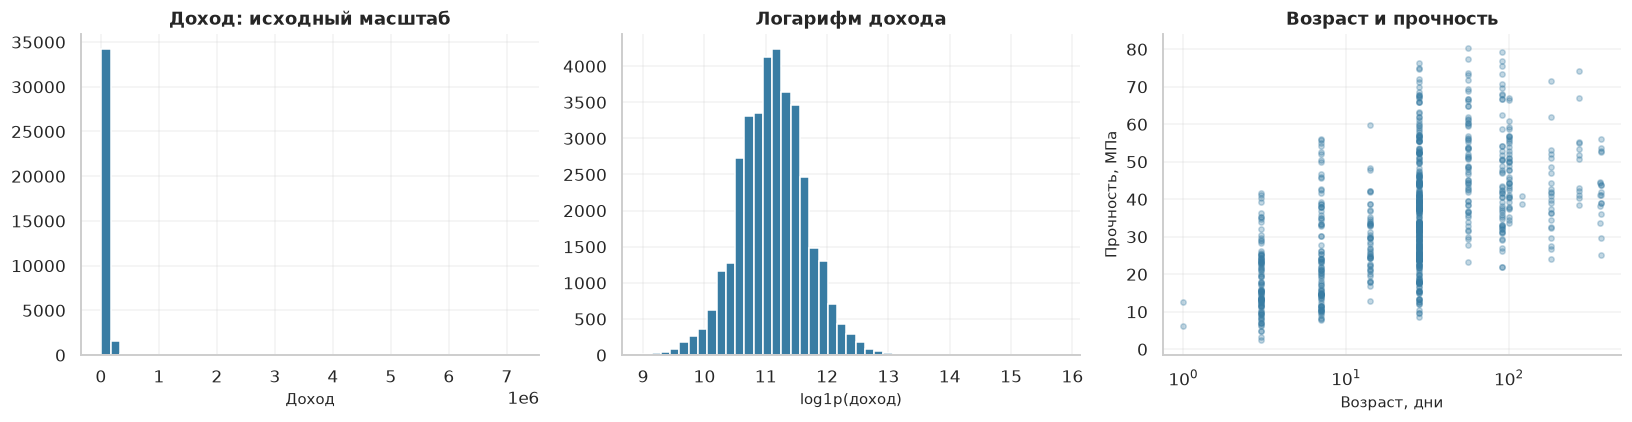

In [4]:
# EDA не обращается к отложенной выборке; справочные распределения строятся только на train.
c, r = tasks["classification"], tasks["regression"]
show_table(c["y_train"].value_counts().rename("count").to_frame().assign(
    fraction=c["y_train"].value_counts(normalize=True)))
show_table(r["X_train"].join(r["y_train"]).describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(c["X_train"]["person_income"], bins=45)
axes[0].set(title="Доход: исходный масштаб", xlabel="Доход")
axes[1].hist(np.log1p(c["X_train"]["person_income"].clip(lower=0)), bins=45)
axes[1].set(title="Логарифм дохода", xlabel="log1p(доход)")
axes[2].scatter(r["X_train"]["age"], r["y_train"], s=12, alpha=.3)
axes[2].set(xscale="log", xlabel="Возраст, дни", ylabel="Прочность, МПа", title="Возраст и прочность")
plt.tight_layout()
plt.show()

### Наблюдения по данным

Одобренные заявки составляют около 22,2% train: accuracy недостаточно, поэтому
основной метрикой остаётся F1. У дохода длинный правый хвост, но дерево не использует
расстояния между объектами. Для него логарифмирование не обещает такого же выигрыша,
как для KNN или линейных моделей. Связь прочности с возрастом нелинейна; дерево
может описывать её без полиномов, однако на небольшом train легко переобучается.

## 2. Создание бейзлайна и оценка качества

Исходные модели: **DecisionTreeClassifier(criterion="gini")** и
**DecisionTreeRegressor(criterion="squared_error")** с `random_state=42`.
Остальные параметры исходные: `max_depth=None`, `min_samples_split=2`,
`min_samples_leaf=1`, `min_impurity_decrease=0`, без весов классов.

Пропуски заполняю медианой / модой, категории кодирую полным one-hot.
Масштабирование исходному дереву не добавляю. Для ориентира обучу Dummy:
наиболее частый класс или медиана прочности.

Вероятность класса — его доля в листе. Выбираю класс с наибольшей вероятностью;
при равенстве — первый класс, то есть 0. Порог фиксирован и не подбирается по test.

### Pipeline и запись результатов

Объединю подготовку и модель, чтобы исключить утечку статистик из валидации.
Функция оценки сохранит метрики, время, предсказания и сведения об общем протоколе.
Её же использую для всех последующих вариантов.

In [5]:
# Подготовка признаков одинакова для sklearn и собственной модели.
"""Общие разбиения №1–2 и подготовка данных для решающих деревьев."""

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor


def sklearn_model(task, **params):
    cls = DecisionTreeClassifier if task == "classification" else DecisionTreeRegressor
    return cls(random_state=SEED, **params)


def make_pipeline(X, task, mode="raw", estimator=None):
    if mode not in ("raw", "scaled", "log", "engineered"):
        raise ValueError(f"Неизвестное представление {mode}")
    categorical = [column for column in CATEGORICAL if column in X]
    numeric = [column for column in X if column not in categorical]
    if mode == "engineered":
        numeric += (["employment_age_ratio", "credit_history_age_ratio"] if task == "classification"
                    else ["binder", "water_binder_ratio", "aggregate_binder_ratio"])
    steps = [("impute", SimpleImputer(strategy="median"))]
    if mode == "scaled":
        steps.append(("scale", StandardScaler()))
    transforms = [("numeric", Pipeline(steps), numeric)]
    if categorical:
        transforms.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical))
    return Pipeline([
        ("features", TaskFeatures(task, mode)),
        ("preprocess", ColumnTransformer(transforms, sparse_threshold=0)),
        ("model", sklearn_model(task) if estimator is None else estimator),
    ])

records, fitted, predictions, complexity = [], {}, {}, []
def fit_evaluate(task, name, model, mode):
    """Обучение только на train; test служит только итоговой оценкой."""
    t = tasks[task]
    started = perf_counter()
    model.fit(t["X_train"], t["y_train"])
    fit_seconds = perf_counter() - started
    started = perf_counter()
    if task == "classification":
        probabilities = model.predict_proba(t["X_test"])
        prediction = model.classes_[probabilities.argmax(axis=1)]
        proba = probabilities[:, 1]
    else:
        prediction, proba = model.predict(t["X_test"]), None
    predict_seconds = perf_counter() - started
    scores = evaluate(task, t["y_test"], prediction, proba)
    estimator = model.named_steps["model"]
    records.append(dict(lab=3, algorithm="Dummy" if name == "dummy" else
                        ("DecisionTreeClassifier" if task == "classification" else "DecisionTreeRegressor"),
                        model=name, implementation="custom" if name.startswith("custom") else "sklearn",
                        stage="dummy" if name == "dummy" else name.split("_")[1], task=task,
                        dataset=t["spec"]["name"], target=t["spec"]["target"],
                        feature_set=",".join(t["X_train"].columns), dataset_sha=t["spec"]["sha256"],
                        split_sha=t["split_sha"], protocol_id=t["spec"]["protocol_id"],
                        n_train=len(t["X_train"]), n_test=len(t["X_test"]),
                        fit_seconds=fit_seconds, predict_seconds=predict_seconds,
                        representation=mode, estimator=type(estimator).__name__, **scores))
    fitted[task, name] = model
    predictions[task, name] = (prediction, proba)
    pd.DataFrame({"row_id": t["X_test"].index, "truth": t["y_test"].to_numpy(),
                  "prediction": prediction, **({"probability": proba} if proba is not None else {})}).to_csv(
        RESULTS / f"predictions_{task}_{name}.csv", index=False)
    if name != "dummy":
        train_pred = model.predict(t["X_train"])
        train_prob = model.predict_proba(t["X_train"])[:, 1] if task == "classification" else None
        train_scores = evaluate(task, t["y_train"], train_pred, train_prob)
        complexity.append(dict(task=task, model=name, depth=estimator.get_depth(),
                               leaves=estimator.get_n_leaves(),
                               nodes=estimator.node_count_ if hasattr(estimator, "node_count_") else estimator.tree_.node_count,
                               train_score=train_scores["f1" if task == "classification" else "mae"]))
    return scores

def show_metrics(frame):
    for task in tasks:
        cols = (["model", "f1", "precision", "recall", "balanced_accuracy", "accuracy", "roc_auc", "average_precision"]
                if task == "classification" else ["model", "mae", "rmse", "r2"])
        show_table(frame.loc[frame.task == task, cols].reset_index(drop=True), TASK_NAMES[task])

### Качество исходных моделей

Сначала посчитаю CV исходного дерева на полном train, затем обучу его на всём train
и оценю на отложенной выборке. Настройки улучшений и сетка ниже заданы заранее;
результаты test не используются для их изменения.

In [6]:
# Исходные параметры фиксируются до проверки гипотез.
base_models, hypothesis_records = {}, []
for task, t in tasks.items():
    base_models[task] = make_pipeline(t["X_train"], task, "raw")
    scores = cross_val_score(base_models[task], t["X_train"], t["y_train"],
                             cv=t["cv"], scoring=scoring[task], n_jobs=1, error_score="raise")
    hypothesis_records.append(dict(task=task, mode="raw", cv_mean=float(scores.mean()),
                                   cv_std=float(scores.std()), folds=scores.tolist()))
    dummy = DummyClassifier(strategy="most_frequent") if task == "classification" else DummyRegressor(strategy="median")
    fit_evaluate(task, "dummy", make_pipeline(t["X_train"], task, "raw", dummy), "raw")
    fit_evaluate(task, "sklearn_baseline", clone(base_models[task]), "raw")
show_table(pd.DataFrame(hypothesis_records).drop(columns="folds"), "Исходные CV-оценки (F1 / отрицательная MAE)")
show_metrics(pd.DataFrame(records))
show_table(pd.DataFrame(complexity), "Сложность и качество на train")

Задача,Признаки,Среднее CV,Разброс CV
Классификация,raw,0.7098,0.0083
Регрессия,raw,-5.8527,0.7382


Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.7326,0.7263,0.7390,0.8297,0.8801,0.8297,0.5947


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,5.8641,9.2407,0.7354


Задача,Модель,Глубина,Листья,Узлы,Качество train
Классификация,sklearn · исходная,33,2861,5721,1.0000
Регрессия,sklearn · исходная,24,784,1567,0.0666


### Вывод по бейзлайну

Неограниченное дерево может создавать листья из одного объекта: качество на train
тогда близко к идеальному, но это не гарантирует обобщения. Сопоставлю train с CV
и test в таблицах выше. Dummy помогает увидеть, что высокая accuracy сама по себе
не означает обнаружение класса одобрения. Для регрессии нулевая ошибка train
у глубокого дерева означает запоминание измерений, а не точный прогноз новых рецептур.

## 3. Улучшение бейзлайна
### Гипотезы

| Гипотеза | Что проверю | Ожидаемый результат |
|:--|:--|:--|
| H1 · масштаб | StandardScaler при исходных параметрах | Существенного выигрыша не ожидаю: порядок значений сохраняется |
| H2 · логарифмирование | log1p дохода / возраста | Порядок сохраняется; возможны отличия порогов для новых объектов |
| H3 · новые признаки | Отношения стажа и истории к возрасту; состав бетона | Упростятся правила, которые трудно представить одним исходным порогом |
| H4 · ограничение роста | Глубина и минимум объектов в листе | Снизится переобучение |
| H5 · веса классов | None и balanced | Может вырасти recall, но F1 зависит и от precision |

В `engineered` входят log-преобразование и отношения. Для заявок добавляю
`employment_age_ratio`, `credit_history_age_ratio`. Для бетона — сумму вяжущего
`cement+slag+fly_ash`, `water_binder_ratio` и `aggregate_binder_ratio`.
Все эти признаки вычисляются без целевой переменной.

In [7]:
# Изолированно проверю преобразования при исходных параметрах дерева.
for task, t in tasks.items():
    for mode in ["scaled", "log", "engineered"]:
        scores = cross_val_score(make_pipeline(t["X_train"], task, mode), t["X_train"], t["y_train"],
                                 cv=t["cv"], scoring=scoring[task], n_jobs=1, error_score="raise")
        hypothesis_records.append(dict(task=task, mode=mode, cv_mean=float(scores.mean()),
                                       cv_std=float(scores.std()), folds=scores.tolist()))
hypotheses = pd.DataFrame(hypothesis_records)
hypotheses.to_json(RESULTS / "hypotheses.json", orient="records", indent=2)
show_table(hypotheses.drop(columns="folds"), "F1 / отрицательная MAE: больше — лучше")

Задача,Признаки,Среднее CV,Разброс CV
Классификация,raw,0.7098,0.0083
Регрессия,raw,-5.8527,0.7382
Классификация,scaled,0.7095,0.0087
Классификация,log,0.7097,0.0082
Классификация,engineered,0.7074,0.0083
Регрессия,scaled,-5.8479,0.7419
Регрессия,log,-5.8575,0.7364
Регрессия,engineered,-5.2704,0.3991


### Подбор параметров на кросс-валидации

Совместно сравню `raw` и `engineered`, глубины **3, 5, 8, 12, None**,
минимум объектов в листе **1, 5, 20** для классификации и **1, 3, 8** для регрессии.
В классификации также проверю обычные и сбалансированные веса классов.
Это **60 конфигураций × 3 фолда** и **30 конфигураций × 3 фолда** соответственно.

`min_samples_split=2`, `min_impurity_decrease=0` и критерии оставляю фиксированными.
Масштаб и log отдельно в сетку не включаю: проверка выше служит исследованием их эффекта,
а основной поиск посвящён сложности и новым признакам. `raw` с исходными параметрами
присутствует в сетке, поэтому исходное решение тоже может победить.

Выбираю максимум среднего F1 либо отрицательной MAE. Разброс по трём фолдам —
описательная характеристика, а не доверительный интервал. Повторный поиск по тем же
фолдам может оптимистично оценивать победителя, поэтому отдельно показываю test.

In [8]:
# Все варианты перебираются по полному train; test в GridSearchCV не передаётся.
searches, selected = {}, {}
for task, t in tasks.items():
    grid = []
    for mode in ["raw", "engineered"]:
        pipe = make_pipeline(t["X_train"], task, mode)
        params = {"features": [pipe.named_steps["features"]],
                  "preprocess": [pipe.named_steps["preprocess"]],
                  "model__max_depth": [3, 5, 8, 12, None],
                  "model__min_samples_leaf": [1, 5, 20] if task == "classification" else [1, 3, 8]}
        if task == "classification":
            params["model__class_weight"] = [None, "balanced"]
        grid.append(params)
    search = GridSearchCV(base_models[task], grid, cv=t["cv"], scoring=scoring[task],
                          n_jobs=1, error_score="raise", refit=True, return_train_score=True)
    search.fit(t["X_train"], t["y_train"])
    searches[task] = search
    best = search.best_estimator_
    estimator = best.named_steps["model"]
    params = {"max_depth": estimator.max_depth, "min_samples_leaf": estimator.min_samples_leaf}
    if task == "classification":
        params["class_weight"] = estimator.class_weight
    selected[task] = {"mode": best.named_steps["features"].mode, "params": params,
                      "estimator": type(estimator).__name__, "cv_score": float(search.best_score_)}
    cv_rows = []
    for index, config in enumerate(search.cv_results_["params"]):
        cv_rows.append({"mode": config["features"].mode,
                        "max_depth": "None" if config["model__max_depth"] is None else config["model__max_depth"],
                        "min_samples_leaf": config["model__min_samples_leaf"],
                        "class_weight": config.get("model__class_weight"),
                        **{key: search.cv_results_[key][index] for key in
                           ["mean_test_score", "std_test_score", "rank_test_score", "mean_train_score",
                            "split0_test_score", "split1_test_score", "split2_test_score"]}})
    table = pd.DataFrame(cv_rows)
    table.to_csv(RESULTS / f"cv_{task}.csv", index=False)
    show_table(table.sort_values("rank_test_score").head(8), TASK_NAMES[task] + ": лучшие CV-конфигурации")
    show_table(pd.DataFrame([{**params, "mode": selected[task]["mode"],
                              "Средний F1" if task == "classification" else "Средняя MAE, МПа":
                              search.best_score_ if task == "classification" else -search.best_score_}]),
               "Выбранная конфигурация")
(RESULTS / "selected.json").write_text(json.dumps(selected, ensure_ascii=False, indent=2));

,Признаки,Предел глубины,Минимум в листе,Веса классов,Среднее CV,Разброс CV,Место,Среднее train,split0_test_score,split1_test_score,split2_test_score
14,raw,None,20,—,0.7269,0.0083,1,0.7904,0.7152,0.7329,0.7325
44,engineered,None,20,—,0.7211,0.0091,2,0.7909,0.7124,0.7173,0.7336
13,raw,None,5,—,0.7195,0.0087,3,0.8854,0.7077,0.7222,0.7286
10,raw,12,5,—,0.7183,0.0027,4,0.7726,0.7160,0.7168,0.7222
43,engineered,None,5,—,0.7150,0.0080,5,0.8880,0.7037,0.7193,0.7218
9,raw,12,1,—,0.7141,0.0017,6,0.7831,0.7116,0.7152,0.7154
40,engineered,12,5,—,0.7126,0.0013,7,0.7704,0.7133,0.7108,0.7138
11,raw,12,20,—,0.7124,0.0036,8,0.7519,0.7151,0.7073,0.7146


Предел глубины,Минимум в листе,Веса классов,Признаки,Средний F1
—,20,—,raw,0.7269


,Признаки,Предел глубины,Минимум в листе,Веса классов,Среднее CV,Разброс CV,Место,Среднее train,split0_test_score,split1_test_score,split2_test_score
24,engineered,12,1,—,-5.2542,0.4118,1,-0.2881,-5.5078,-5.5816,-4.6734
27,engineered,None,1,—,-5.2704,0.3991,2,-0.0666,-5.5769,-5.5277,-4.7068
23,engineered,8,8,—,-5.2722,0.2093,3,-3.6864,-5.4240,-5.4163,-4.9762
26,engineered,12,8,—,-5.2834,0.2303,4,-3.6581,-5.3919,-5.4951,-4.9632
29,engineered,None,8,—,-5.2834,0.2303,4,-3.6581,-5.3919,-5.4951,-4.9632
25,engineered,12,3,—,-5.4905,0.4408,6,-2.0972,-5.9182,-5.6695,-4.8839
28,engineered,None,3,—,-5.5980,0.5408,7,-2.0899,-5.9182,-6.0393,-4.8363
22,engineered,8,3,—,-5.6630,0.4609,8,-2.5458,-6.1076,-5.8536,-5.0279


Предел глубины,Минимум в листе,Признаки,"Средняя MAE, МПа"
12,1,engineered,5.2542


### Результаты проверки гипотез

Для преобразований сравню каждое изменение с предыдущим. Эффект ограничения роста
и весов посмотрю внутри полной сетки, выбирая лучшие варианты соответствующей группы.
Это описательное сравнение CV, без утверждения о статистической значимости.

Задача,Гипотеза,Изменение CV-score
Классификация,H1 · масштаб,-0.0003
Классификация,H2 · log,-0.0001
Классификация,H3 · отношения после log,-0.0023
Классификация,H4 · лучшие ограниченные / неограниченные,0.0171
Классификация,H5 · лучшие balanced / обычные веса,-0.0165
Регрессия,H1 · масштаб,0.0047
Регрессия,H2 · log,-0.0048
Регрессия,H3 · отношения после log,0.5870
Регрессия,H4 · лучшие ограниченные / неограниченные,0.0162


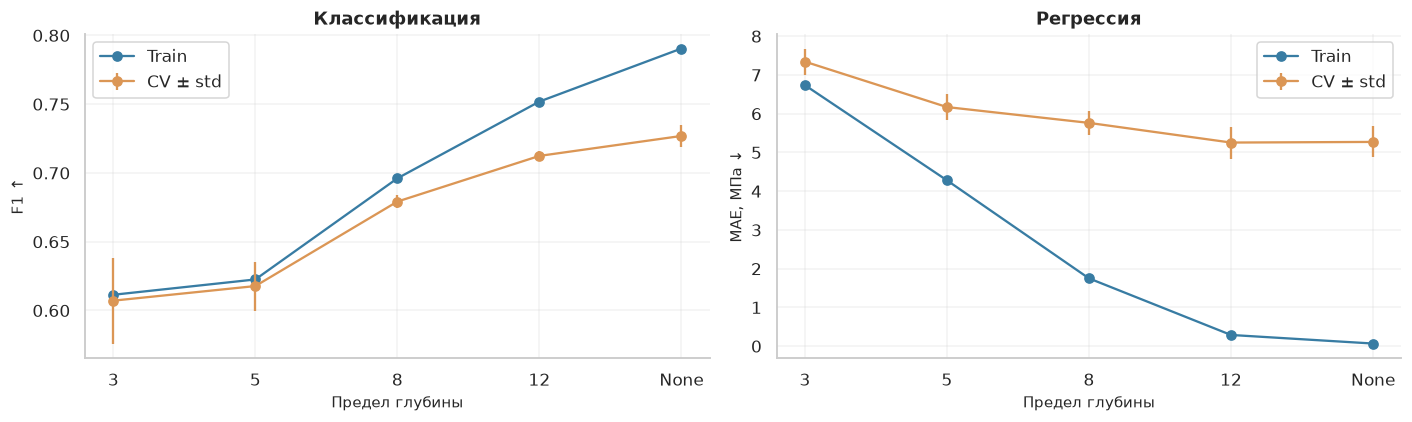

In [9]:
# Положительная разность CV-score означает рост F1 или уменьшение MAE.
hypothesis_rows = []
for task in tasks:
    h = hypotheses[hypotheses.task == task].set_index("mode")
    for label, new, old in [("H1 · масштаб", "scaled", "raw"),
                             ("H2 · log", "log", "raw"),
                             ("H3 · отношения после log", "engineered", "log")]:
        hypothesis_rows.append({"task": task, "Гипотеза": label,
                                "Изменение CV-score": h.loc[new, "cv_mean"] - h.loc[old, "cv_mean"]})
    cv = pd.read_csv(RESULTS / f"cv_{task}.csv", keep_default_na=False)
    unrestricted = cv[(cv.max_depth.astype(str) == "None") & (cv.min_samples_leaf == 1)]
    restricted = cv[~((cv.max_depth.astype(str) == "None") & (cv.min_samples_leaf == 1))]
    hypothesis_rows.append({"task": task, "Гипотеза": "H4 · лучшие ограниченные / неограниченные",
                            "Изменение CV-score": restricted.mean_test_score.max() - unrestricted.mean_test_score.max()})
    if task == "classification":
        hypothesis_rows.append({"task": task, "Гипотеза": "H5 · лучшие balanced / обычные веса",
                                "Изменение CV-score": cv[cv.class_weight == "balanced"].mean_test_score.max()
                                - cv[cv.class_weight != "balanced"].mean_test_score.max()})
show_table(pd.DataFrame(hypothesis_rows))
# Покажу train/CV при разной глубине с остальными параметрами победителя.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task in zip(axes, tasks):
    cv = pd.read_csv(RESULTS / f"cv_{task}.csv", keep_default_na=False)
    p = selected[task]["params"]
    subset = cv[(cv["mode"] == selected[task]["mode"]) & (cv.min_samples_leaf == p["min_samples_leaf"])]
    if task == "classification":
        subset = subset[subset.class_weight == (p["class_weight"] or "")]
    subset = subset.copy()
    subset["order"] = subset.max_depth.astype(str).map({"3": 0, "5": 1, "8": 2, "12": 3, "None": 4})
    subset = subset.sort_values("order")
    sign = 1 if task == "classification" else -1
    ax.plot(subset.max_depth.astype(str), sign * subset.mean_train_score, marker="o", label="Train")
    ax.errorbar(subset.max_depth.astype(str), sign * subset.mean_test_score,
                yerr=subset.std_test_score, marker="o", label="CV ± std")
    ax.set(title=TASK_NAMES[task], xlabel="Предел глубины", ylabel="F1 ↑" if sign == 1 else "MAE, МПа ↓")
    ax.legend()
plt.tight_layout()
plt.show()

### Улучшенные модели sklearn на test

Зафиксирую выбранные параметры, переобучу Pipeline на всём train и посчитаю
те же метрики на test. Сравню их с исходными моделями. После этого параметры не меняю.

In [10]:
# Конфигурации выбраны по CV; test используется только для отчёта.
for task in tasks:
    fit_evaluate(task, "sklearn_improved", clone(searches[task].best_estimator_), selected[task]["mode"])
show_metrics(pd.DataFrame(records))
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    group = pd.DataFrame(records).query("task == @task").set_index("model")
    old, new = group.loc["sklearn_baseline", metric], group.loc["sklearn_improved", metric]
    display(Markdown(f"**{TASK_NAMES[task]}:** исходная {'F1' if task == 'classification' else 'MAE'} "
                     f"**{old:.5f}**, улучшенная **{new:.5f}**, изменение **{new-old:+.5f}**. "
                     f"Выигрыш на CV не гарантирует такой же выигрыш на test."))

Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.7326,0.7263,0.7390,0.8297,0.8801,0.8297,0.5947
sklearn · улучшенная,0.7376,0.7839,0.6965,0.8208,0.8899,0.9388,0.8524


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,5.8641,9.2407,0.7354
sklearn · улучшенная,4.4701,7.0349,0.8466


**Классификация:** исходная F1 **0.73259**, улучшенная **0.73762**, изменение **+0.00503**. Выигрыш на CV не гарантирует такой же выигрыш на test.

**Регрессия:** исходная MAE **5.86415**, улучшенная **4.47014**, изменение **-1.39401**. Выигрыш на CV не гарантирует такой же выигрыш на test.

## 4. Самостоятельная реализация CART
### Как строится дерево

В каждом узле перебираю признаки и пороги между соседними различными значениями.
Выбираю разбиение с минимальной суммой взвешенных нечистот потомков:

$$\Delta I=I(S)-\frac{W_L}{W_S}I(S_L)-\frac{W_R}{W_S}I(S_R).$$

Для классификации использую $Gini(S)=1-\sum_k p_k^2$, где $p_k$ — взвешенная доля
класса в узле. В листе возвращаю эти вероятности. Для `balanced` вес объекта класса $k$
равен $n/(K n_k)$; он вычисляется только по обучающей части.

Для регрессии $I(S)=\frac{1}{n_S}\sum_{i\in S}(y_i-\bar y_S)^2$,
прогноз листа — среднее. Это критерий MSE / SSE, хотя итоговую модель выбираю по MAE:
критерий локального разбиения и метрика выбора могут отличаться.

Сортировка и накопленные суммы позволяют оценить все пороги признака за линейный проход
после сортировки. Ограничения роста: `max_depth`, `min_samples_split`, `min_samples_leaf`,
`min_impurity_decrease`. Последнее сравнивается с $(W_S/W_{root})\Delta I$.
При чистой цели или отсутствии допустимых разбиений оставляю лист.
Нулевой выигрыш при нулевом ограничении допустим, чтобы дерево могло раскрывать взаимодействия.

**Что реализовано самостоятельно:** поиск порогов, расчёт Gini/SSE, рост дерева через стек,
веса классов, прогнозы, вероятности, глубина, число листьев и impurity-based важность признаков.
sklearn нужен только для интерфейса, проверки входов и Pipeline; его деревья внутри реализации
не вызываются. Поддерживаются плотные числовые матрицы без пропусков после предобработки.
Категории обрабатываются one-hot; pruning, случайный выбор признаков и другие критерии не реализуются.

Для сопоставимости входы дерева привожу к float32. При равных выигрышах выбираю первый
признак и первый порог; sklearn может выбирать другой равноценный признак. Поэтому
побитовое совпадение глубоких деревьев не требуется. Различия прогнозов измерю ниже.

In [11]:
# Этот же исходный код находится в lab_3/src/decision_tree.py и проверяется тестами.
"""CART на NumPy: полный перебор порогов, Gini и squared_error.

sklearn используется только для интерфейса estimator и проверки входов.
Поиск разбиений, рост дерева, вероятности и прогноз реализованы самостоятельно.
"""

from numbers import Integral
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.utils.multiclass import check_classification_targets
from sklearn.utils.validation import check_is_fitted, validate_data


class _CART(BaseEstimator):
    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 min_impurity_decrease=0.0):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease

    def _validate_parameters(self):
        for name, lower in [("max_depth", 1), ("min_samples_split", 2), ("min_samples_leaf", 1)]:
            value = getattr(self, name)
            if name == "max_depth" and value is None:
                continue
            if isinstance(value, bool) or not isinstance(value, Integral) or value < lower:
                raise ValueError(f"{name} должен быть целым числом >= {lower}")
        if not np.isfinite(self.min_impurity_decrease) or self.min_impurity_decrease < 0:
            raise ValueError("min_impurity_decrease должен быть конечным и >= 0")

    def _fit(self, X, y, classification):
        self._validate_parameters()
        X, y = validate_data(self, X, y, dtype=np.float32, y_numeric=not classification)
        if y.ndim != 1:
            raise ValueError("Поддерживается одна целевая переменная")
        self._classification = classification
        if classification:
            check_classification_targets(y)
            self.classes_, target = np.unique(y, return_inverse=True)
            self.n_classes_ = len(self.classes_)
            if self.class_weight not in (None, "balanced"):
                raise ValueError("Поддерживаются class_weight=None и balanced")
            counts = np.bincount(target, minlength=self.n_classes_)
            weights = np.ones(len(y)) if self.class_weight is None else len(y) / (self.n_classes_ * counts[target])
        else:
            # Центрирование уменьшает потерю точности при вычислении SSE.
            self.target_offset_ = float(np.mean(y))
            target = np.asarray(y, dtype=np.float64) - self.target_offset_
            weights = np.ones(len(y))
        self.nodes_ = []
        self.feature_importances_ = np.zeros(X.shape[1])
        self.max_depth_ = 0
        self.n_leaves_ = 0
        total_weight = weights.sum()
        # Стек вместо рекурсии позволяет строить и глубокие деревья.
        pending = [(np.arange(len(y)), 0, None, None)]
        while pending:
            indices, depth, parent, side = pending.pop()
            values, w = target[indices], weights[indices]
            mass = w.sum()
            if classification:
                histogram = np.bincount(values, weights=w, minlength=self.n_classes_)
                value = histogram / mass
                impurity = max(0.0, 1.0 - value @ value)
                parent_cost = mass * impurity
            else:
                mean = values.mean()
                value = mean + self.target_offset_
                parent_cost = float(np.sum((values - mean) ** 2))
                impurity = parent_cost / mass
            node = dict(feature=-1, threshold=np.nan, left=-1, right=-1, value=value,
                        n_samples=len(indices), impurity=impurity, depth=depth)
            node_id = len(self.nodes_)
            self.nodes_.append(node)
            if parent is not None:
                self.nodes_[parent][side] = node_id
            self.max_depth_ = max(self.max_depth_, depth)
            best = None
            best_cost = np.inf
            can_split = (len(indices) >= max(self.min_samples_split, 2 * self.min_samples_leaf)
                         and (self.max_depth is None or depth < self.max_depth)
                         and impurity > np.finfo(float).eps)
            if can_split:
                for feature in range(X.shape[1]):
                    order = np.argsort(X[indices, feature], kind="stable")
                    sorted_indices = indices[order]
                    x = X[sorted_indices, feature].astype(np.float64)
                    positions = np.arange(1, len(x))
                    # Почти равные float32-значения не образуют отдельный порог.
                    valid = ((x[1:] > x[:-1] + 1e-7)
                             & (positions >= self.min_samples_leaf)
                             & (len(x) - positions >= self.min_samples_leaf))
                    if not valid.any():
                        continue
                    ordered_target, ordered_w = target[sorted_indices], weights[sorted_indices]
                    if classification:
                        onehot = np.zeros((len(x), self.n_classes_))
                        onehot[np.arange(len(x)), ordered_target] = ordered_w
                        left_counts = np.cumsum(onehot, axis=0)[:-1]
                        right_counts = histogram - left_counts
                        left_mass = np.cumsum(ordered_w)[:-1]
                        right_mass = mass - left_mass
                        costs = (mass - (left_counts ** 2).sum(axis=1) / left_mass
                                 - (right_counts ** 2).sum(axis=1) / right_mass)
                    else:
                        cumulative = np.cumsum(ordered_target)[:-1]
                        cumulative2 = np.cumsum(ordered_target ** 2)[:-1]
                        total, total2 = ordered_target.sum(), np.sum(ordered_target ** 2)
                        costs = (cumulative2 - cumulative ** 2 / positions
                                 + total2 - cumulative2 - (total - cumulative) ** 2 / (len(x) - positions))
                    costs[~valid] = np.inf
                    cut = int(np.argmin(costs))
                    # При равенстве сохраняется первый признак и первый порог.
                    if costs[cut] < best_cost - 1e-12:
                        best_cost = float(costs[cut])
                        threshold = x[cut] / 2.0 + x[cut + 1] / 2.0
                        best = (feature, threshold, sorted_indices[:cut + 1], sorted_indices[cut + 1:])
            gain = 0.0 if best is None else max(0.0, parent_cost - best_cost)
            if best is None or gain / total_weight + 1e-15 < self.min_impurity_decrease:
                self.n_leaves_ += 1
                continue
            feature, threshold, left, right = best
            node.update(feature=feature, threshold=threshold)
            self.feature_importances_[feature] += gain
            pending.append((right, depth + 1, node_id, "right"))
            pending.append((left, depth + 1, node_id, "left"))
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        self.node_count_ = len(self.nodes_)
        return self

    def _values(self, X):
        check_is_fitted(self, "nodes_")
        X = validate_data(self, X, reset=False, dtype=np.float32)
        shape = (len(X), self.n_classes_) if self._classification else (len(X),)
        result = np.empty(shape)
        pending = [(0, np.arange(len(X)))]
        while pending:
            node_id, rows = pending.pop()
            if not len(rows):
                continue
            node = self.nodes_[node_id]
            if node["feature"] < 0:
                result[rows] = node["value"]
            else:
                goes_left = X[rows, node["feature"]] <= node["threshold"]
                pending.append((node["left"], rows[goes_left]))
                pending.append((node["right"], rows[~goes_left]))
        return result

    def get_depth(self):
        check_is_fitted(self, "nodes_")
        return self.max_depth_

    def get_n_leaves(self):
        check_is_fitted(self, "nodes_")
        return self.n_leaves_


class NumpyDecisionTreeClassifier(ClassifierMixin, _CART):
    """CART с Gini, вероятностями в листьях и необязательными весами классов."""

    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 min_impurity_decrease=0.0, class_weight=None):
        super().__init__(max_depth, min_samples_split, min_samples_leaf, min_impurity_decrease)
        self.class_weight = class_weight

    def fit(self, X, y):
        return self._fit(X, y, classification=True)

    def predict_proba(self, X):
        return self._values(X)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return self.classes_[probabilities.argmax(axis=1)]


class NumpyDecisionTreeRegressor(RegressorMixin, _CART):
    """CART с минимизацией SSE и средним целевой переменной в листе."""

    def fit(self, X, y):
        return self._fit(X, y, classification=False)

    def predict(self, X):
        return self._values(X)

### Проверка математического смысла на небольшом примере

До больших экспериментов проверю известный порог, вероятности в листьях и средний
прогноз регрессии. Полные проверки находятся в `lab_3/tests/test_decision_tree.py`:
там дополнительно проверяются взвешенный Gini полным перебором, устойчивость SSE,
совпадение со sklearn при однозначных разбиениях и ограничения роста.

In [12]:
# Простые ответы можно проверить вручную; assert остановит запуск при ошибке.
X_demo = np.arange(6, dtype=float)[:, None]
c_demo = NumpyDecisionTreeClassifier(max_depth=1).fit(X_demo, [0, 0, 0, 1, 1, 1])
r_demo = NumpyDecisionTreeRegressor(max_depth=1).fit(X_demo, [1, 1, 1, 5, 5, 5])
assert c_demo.nodes_[0]["threshold"] == 2.5
np.testing.assert_allclose(c_demo.predict_proba([[0], [5]]), [[1, 0], [0, 1]])
np.testing.assert_allclose(r_demo.predict([[0], [5]]), [1, 5])
print("Проверены порог 2.5, вероятности [1,0] / [0,1] и прогнозы 1 / 5.")

Проверены порог 2.5, вероятности [1,0] / [0,1] и прогнозы 1 / 5.


### Исходные собственные модели

Обучу свою классификацию и регрессию с исходными параметрами, без масштабирования
и дополнительных признаков. Сопоставлю с исходными sklearn на тех же объектах.

In [13]:
# Для исходной пары совпадают критерии, признаки и ограничения роста.
for task, t in tasks.items():
    cls = NumpyDecisionTreeClassifier if task == "classification" else NumpyDecisionTreeRegressor
    fit_evaluate(task, "custom_baseline", make_pipeline(t["X_train"], task, "raw", cls()), "raw")
show_metrics(pd.DataFrame(records).query("model in ['sklearn_baseline', 'custom_baseline']"))
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    m = pd.DataFrame(records).query("task == @task").set_index("model")
    display(Markdown(f"**{TASK_NAMES[task]}:** разность своей и sklearn исходной модели по "
                     f"{'F1' if task == 'classification' else 'MAE'} — "
                     f"**{m.loc['custom_baseline', metric] - m.loc['sklearn_baseline', metric]:+.6f}**. "
                     "Одинаковый критерий не требует одинакового выбора при равных выигрышах."))

Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
sklearn · исходная,0.7326,0.7263,0.7390,0.8297,0.8801,0.8297,0.5947
своя · исходная,0.7252,0.7157,0.7350,0.8258,0.8762,0.8258,0.5849


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
sklearn · исходная,5.8641,9.2407,0.7354
своя · исходная,5.7859,9.0571,0.7458


**Классификация:** разность своей и sklearn исходной модели по F1 — **-0.007380**. Одинаковый критерий не требует одинакового выбора при равных выигрышах.

**Регрессия:** разность своей и sklearn исходной модели по MAE — **-0.078281**. Одинаковый критерий не требует одинакового выбора при равных выигрышах.

### Перенос техник улучшенного бейзлайна

Передам собственной модели ровно те признаки, глубину, минимум объектов в листе
и веса классов, которые выбраны для sklearn по CV. Отдельно параметры своей модели
по test не подбираю. Это проверка переноса улучшений, а не независимый поиск её оптимума.

In [14]:
# Все улучшения переносятся без повторного подбора.
for task, t in tasks.items():
    cls = NumpyDecisionTreeClassifier if task == "classification" else NumpyDecisionTreeRegressor
    config = selected[task]
    model = make_pipeline(t["X_train"], task, config["mode"], cls(**config["params"]))
    fit_evaluate(task, "custom_improved", model, config["mode"])
metrics = pd.DataFrame(records)
metrics.to_csv(RESULTS / "metrics.csv", index=False)
pd.DataFrame(complexity).to_csv(RESULTS / "complexity.csv", index=False)
show_metrics(metrics)

Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP
Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222
sklearn · исходная,0.7326,0.7263,0.7390,0.8297,0.8801,0.8297,0.5947
sklearn · улучшенная,0.7376,0.7839,0.6965,0.8208,0.8899,0.9388,0.8524
своя · исходная,0.7252,0.7157,0.7350,0.8258,0.8762,0.8258,0.5849
своя · улучшенная,0.7374,0.7827,0.6970,0.8209,0.8897,0.9385,0.8518


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
Dummy,14.5233,18.1552,-0.0215
sklearn · исходная,5.8641,9.2407,0.7354
sklearn · улучшенная,4.4701,7.0349,0.8466
своя · исходная,5.7859,9.0571,0.7458
своя · улучшенная,4.7932,7.5049,0.8254


### Сравнение реализаций и сложности

Покажу долю разных ответов и различия вероятностей для классификации, среднюю и
максимальную разность прогнозов для регрессии. Сравню глубину и число листьев.
Небольшое отличие выбранного разбиения может менять все дальнейшие узлы глубокого дерева;
поэтому совпадение проверяется тестами на однозначных примерах, а здесь измеряется на реальных данных.

In [15]:
# Измеряю фактическое расхождение; не подгоняю свою реализацию под ответы test.
agreements, agreement_rows = {}, []
for task in tasks:
    agreements[task] = {}
    for stage in ["baseline", "improved"]:
        own, own_prob = predictions[task, "custom_" + stage]
        ref, ref_prob = predictions[task, "sklearn_" + stage]
        if task == "classification":
            difference = {"Доля разных классов": float(np.mean(own != ref)),
                          "Средняя разность вероятностей": float(np.mean(np.abs(own_prob - ref_prob))),
                          "Максимальная разность вероятностей": float(np.max(np.abs(own_prob - ref_prob)))}
        else:
            difference = {"Средняя разность прогнозов, МПа": float(np.mean(np.abs(own - ref))),
                          "Максимальная разность прогнозов, МПа": float(np.max(np.abs(own - ref)))}
        agreements[task][stage] = difference
        agreement_rows.append({"task": task, "stage": stage, **difference})
(RESULTS / "agreement.json").write_text(json.dumps(agreements, ensure_ascii=False, indent=2))
show_table(pd.DataFrame(agreement_rows))
show_table(pd.DataFrame(complexity), "Сложность и качество train (F1 / MAE)")

Задача,Вариант,Доля разных классов,Средняя разность вероятностей,Максимальная разность вероятностей,"Средняя разность прогнозов, МПа","Максимальная разность прогнозов, МПа"
Классификация,baseline,0.0312,0.0312,1.0000,—,—
Классификация,improved,0.0007,0.0022,0.4900,—,—
Регрессия,baseline,—,—,—,1.4193,17.1886
Регрессия,improved,—,—,—,1.2188,25.9381


Задача,Модель,Глубина,Листья,Узлы,Качество train
Классификация,sklearn · исходная,33,2861,5721,1.0000
Регрессия,sklearn · исходная,24,784,1567,0.0666
Классификация,sklearn · улучшенная,21,527,1053,0.8044
Регрессия,sklearn · улучшенная,12,551,1101,0.5174
Классификация,своя · исходная,33,2859,5717,1.0000
Регрессия,своя · исходная,24,781,1561,0.0666
Классификация,своя · улучшенная,21,526,1051,0.8044
Регрессия,своя · улучшенная,12,551,1101,0.5174


### Почему ответы двух реализаций отличаются

Проверю это на самих деревьях, используя только train. Сопоставлю узлы, в которые попали
одни и те же обучающие объекты, и пересчитаю уменьшение нечистоты для обоих выбранных
правил. Если правила различаются, но выигрыш одинаков, это прямое свидетельство
равноценного выбора, а не только предположение о причине расхождений.

Разные признаки могут делить train на те же группы или менять их местами, но иначе
разделять новые объекты. Поэтому одинаковые прогнозы на train не гарантируют совпадения
на test. При перестановке потомков продолжу сопоставление с учётом этой перестановки;
после различного распределения train по ветвям сравнение данной ветви останавливаю.

In [16]:
# Пересчёт критерия в сопоставимых узлах использует только train и выбранные веса.
rule_rows, audit_summary = [], []
for task, t in tasks.items():
    for stage in ["baseline", "improved"]:
        own_pipe = fitted[task, "custom_" + stage]
        ref_pipe = fitted[task, "sklearn_" + stage]
        X = own_pipe[:-1].transform(t["X_train"]).astype(np.float32)
        np.testing.assert_allclose(X, ref_pipe[:-1].transform(t["X_train"]).astype(np.float32))
        y = t["y_train"].to_numpy()
        own, ref = own_pipe[-1], ref_pipe[-1].tree_
        weights = np.ones(len(y))
        if task == "classification" and own.class_weight == "balanced":
            weights = len(y) / (2 * np.bincount(y)[y])
        names = own_pipe.named_steps["preprocess"].get_feature_names_out()
        def cost(rows):
            values = y[rows]
            if task == "regression":
                return np.sum((values - values.mean()) ** 2)
            counts = np.bincount(values, weights=weights[rows], minlength=2)
            return counts.sum() - np.sum(counts ** 2) / counts.sum()
        pending = [(0, 0, np.arange(len(y)))]
        local_rows = []
        while pending:
            a, b, rows = pending.pop()
            node = own.nodes_[a]
            if node["feature"] < 0 or ref.feature[b] < 0:
                continue
            left_own = X[rows, node["feature"]] <= node["threshold"]
            left_ref = X[rows, ref.feature[b]] <= ref.threshold[b]
            same = np.array_equal(left_own, left_ref)
            swapped = np.array_equal(left_own, ~left_ref)
            different_rule = (node["feature"] != ref.feature[b]
                              or abs(node["threshold"] - ref.threshold[b]) > 1e-12)
            if different_rule:
                gain_own = (cost(rows) - cost(rows[left_own]) - cost(rows[~left_own])) / weights[rows].sum()
                gain_ref = (cost(rows) - cost(rows[left_ref]) - cost(rows[~left_ref])) / weights[rows].sum()
                local_rows.append({"task": task, "stage": stage, "Объектов в узле": len(rows),
                                   "Признак своей": names[node["feature"]], "Признак sklearn": names[ref.feature[b]],
                                   "Выигрыш своей": gain_own, "Выигрыш sklearn": gain_ref,
                                   "Разность выигрышей": abs(gain_own - gain_ref),
                                   "Разбиение train": "совпадает" if same else "потомки переставлены" if swapped else "различается"})
            if same:
                pending.extend([(node["left"], ref.children_left[b], rows[left_own]),
                                (node["right"], ref.children_right[b], rows[~left_own])])
            elif swapped:
                pending.extend([(node["left"], ref.children_right[b], rows[left_own]),
                                (node["right"], ref.children_left[b], rows[~left_own])])
        rule_rows.extend(local_rows)
        largest = max((row["Разность выигрышей"] for row in local_rows), default=0.0)
        audit_summary.append({"task": task, "stage": stage, "Различных правил": len(local_rows),
                              "Максимальная разность выигрышей": largest})
        # Наблюдаемое равенство критерия проверяется численно, а не предполагается.
        assert largest < 1e-8
rule_audit = pd.DataFrame(rule_rows)
rule_audit.to_csv(RESULTS / "split_rule_audit.csv", index=False)
show_table(pd.DataFrame(audit_summary), "Проверка равноценных правил на train")
for task in tasks:
    show_table(rule_audit[(rule_audit.task == task) & (rule_audit.stage == "improved")]
               .sort_values("Объектов в узле", ascending=False).head(5).reset_index(drop=True),
               TASK_NAMES[task] + ": примеры разных правил с одинаковым выигрышем")
display(Markdown("У сравниваемых правил разность выигрышей меньше **10⁻⁸**. "
                 "Таким образом, расхождения ответов связаны с равноценными разбиениями. "
                 "В регрессии разные правила могут сохранять обучающие группы, но иначе "
                 "прогнозировать новые составы; разность MAE нельзя считать нулевой."))


Задача,Вариант,Различных правил,Максимальная разность выигрышей
Классификация,baseline,649,0.0000
Классификация,improved,42,0.0000
Регрессия,baseline,337,0.0000
Регрессия,improved,261,0.0000


Задача,Вариант,Объектов в узле,Признак своей,Признак sklearn,Выигрыш своей,Выигрыш sklearn,Разность выигрышей,Разбиение train
Классификация,improved,36000,categorical__previous_loan_defaults_on_file_No,categorical__previous_loan_defaults_on_file_Yes,0.1017,0.1017,0.0000,потомки переставлены
Классификация,improved,126,numeric__person_income,numeric__loan_amnt,0.0473,0.0473,0.0000,совпадает
Классификация,improved,120,categorical__person_gender_female,categorical__person_gender_male,0.0140,0.0140,0.0000,потомки переставлены
Классификация,improved,106,numeric__person_age,numeric__cb_person_cred_hist_length,0.0018,0.0018,0.0000,различается
Классификация,improved,100,numeric__person_age,categorical__person_education_Master,0.0056,0.0056,0.0000,различается


Задача,Вариант,Объектов в узле,Признак своей,Признак sklearn,Выигрыш своей,Выигрыш sklearn,Разность выигрышей,Разбиение train
Регрессия,improved,62,numeric__binder,numeric__water_binder_ratio,9.1873,9.1873,0.0000,потомки переставлены
Регрессия,improved,54,numeric__water,numeric__superplasticizer,7.8392,7.8392,0.0000,потомки переставлены
Регрессия,improved,32,numeric__cement,numeric__water,6.2919,6.2919,0.0000,потомки переставлены
Регрессия,improved,30,numeric__binder,numeric__aggregate_binder_ratio,10.8358,10.8358,0.0000,потомки переставлены
Регрессия,improved,26,numeric__binder,numeric__aggregate_binder_ratio,13.2352,13.2352,0.0000,потомки переставлены


У сравниваемых правил разность выигрышей меньше **10⁻⁸**. Таким образом, расхождения ответов связаны с равноценными разбиениями. В регрессии разные правила могут сохранять обучающие группы, но иначе прогнозировать новые составы; разность MAE нельзя считать нулевой.

### Анализ ошибок улучшенного sklearn

Для классификации посмотрю матрицу ошибок, ROC и Precision–Recall кривые.
Для бетона — фактическую и предсказанную прочность, остатки и абсолютные ошибки.
Это диагностика зафиксированной модели; по этим графикам не меняю параметры.

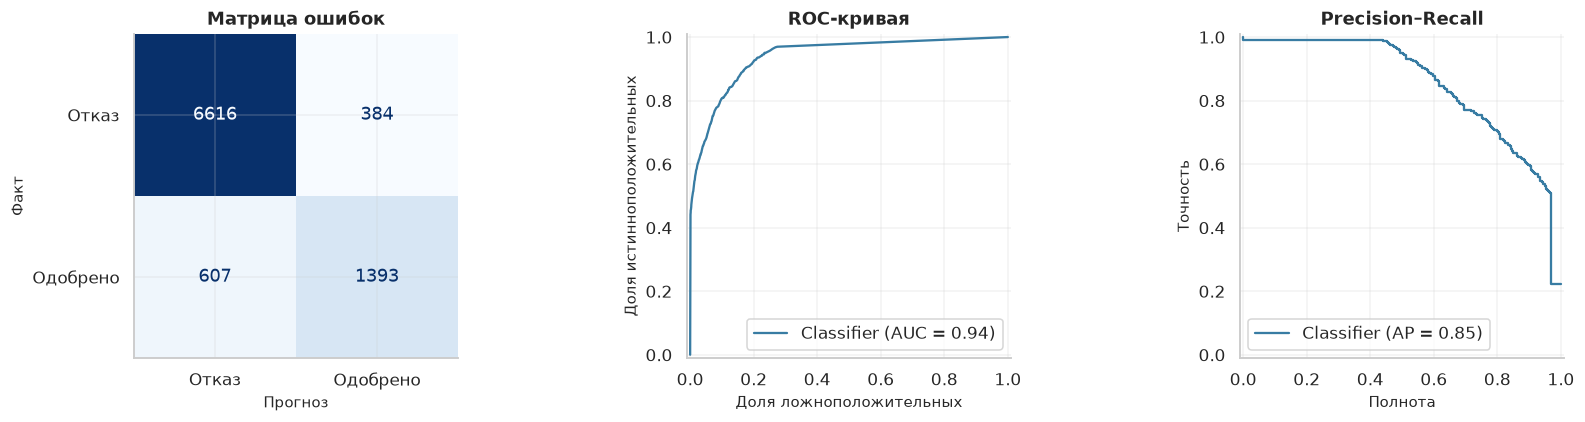

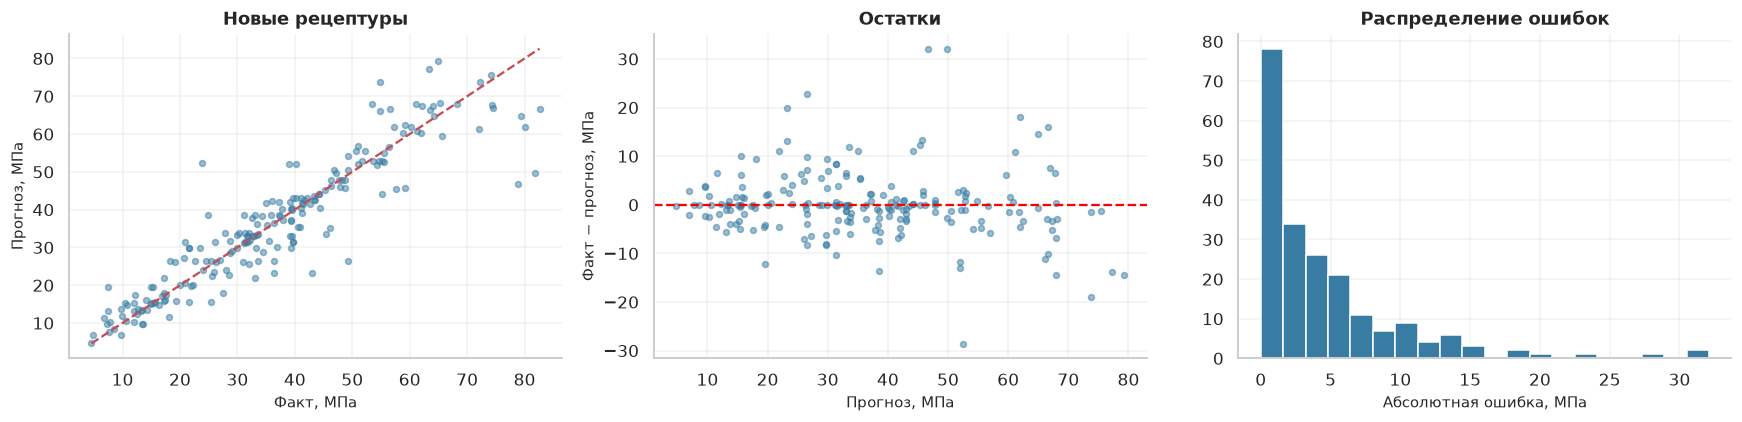

In [17]:
# Визуальная диагностика после выбора конфигурации; test не участвует в дальнейшем подборе.
y_c = tasks["classification"]["y_test"]
pred_c, prob_c = predictions["classification", "sklearn_improved"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_c, pred_c, ax=axes[0], colorbar=False, cmap="Blues", display_labels=["Отказ", "Одобрено"])
RocCurveDisplay.from_predictions(y_c, prob_c, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_c, prob_c, ax=axes[2])
axes[0].set(title="Матрица ошибок", xlabel="Прогноз", ylabel="Факт")
axes[1].set(title="ROC-кривая", xlabel="Доля ложноположительных", ylabel="Доля истинноположительных")
axes[2].set(title="Precision–Recall", xlabel="Полнота", ylabel="Точность")
plt.tight_layout()
plt.show()
y_r = tasks["regression"]["y_test"].to_numpy()
pred_r = predictions["regression", "sklearn_improved"][0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(y_r, pred_r, alpha=.5, s=15)
axes[0].plot([y_r.min(), y_r.max()], [y_r.min(), y_r.max()], "r--")
axes[0].set(xlabel="Факт, МПа", ylabel="Прогноз, МПа", title="Новые рецептуры")
axes[1].scatter(pred_r, y_r - pred_r, alpha=.5, s=15)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Прогноз, МПа", ylabel="Факт − прогноз, МПа", title="Остатки")
axes[2].hist(np.abs(y_r - pred_r), bins=20)
axes[2].set(xlabel="Абсолютная ошибка, МПа", title="Распределение ошибок")
plt.tight_layout()
plt.show()

### Какие ошибки остаются

Ниже свяжу метрики с практическим смыслом: сколько одобрений найдено и насколько
велика ошибка прочности. Даже хорошая F1 не означает, что модель предсказывает риск
дефолта: цель здесь — историческое одобрение. Изолированные большие ошибки регрессии
оцениваю также через RMSE и квантиль абсолютной ошибки.

In [18]:
# Численные выводы пересчитываются при повторном запуске notebook.
m_c = metrics.query("task == 'classification' and model == 'sklearn_improved'").iloc[0]
m_r = metrics.query("task == 'regression' and model == 'sklearn_improved'").iloc[0]
errors = np.abs(tasks["regression"]["y_test"].to_numpy() - predictions["regression", "sklearn_improved"][0])
display(Markdown(f"У улучшенного дерева **precision {m_c.precision:.2%}**, **recall {m_c.recall:.2%}**. "
                 f"Оно пропускает около **{1-m_c.recall:.2%}** фактических одобрений. "
                 f"Для бетона **MAE {m_r.mae:.3f} МПа**, **RMSE {m_r.rmse:.3f} МПа**; "
                 f"90-й процентиль абсолютной ошибки — **{np.quantile(errors, .9):.3f} МПа**. "
                 "RMSE сильнее реагирует на крупные промахи. Эти числа относятся к одному test."))

У улучшенного дерева **precision 78.39%**, **recall 69.65%**. Оно пропускает около **30.35%** фактических одобрений. Для бетона **MAE 4.470 МПа**, **RMSE 7.035 МПа**; 90-й процентиль абсолютной ошибки — **11.152 МПа**. RMSE сильнее реагирует на крупные промахи. Эти числа относятся к одному test.

### Как читать дерево и важности

Покажу первые уровни улучшенных деревьев sklearn. Из-за ограничения глубины рисунка
часть ветвей скрыта; это не полная схема модели. Затем выведу важности, сгруппировав
one-hot уровни обратно в исходные категории.

Важность — нормированная сумма уменьшений нечистоты, а не доказательство причинного
влияния. Она может смещаться к числовым признакам с большим числом возможных порогов
и распределяться между коррелирующими признаками. Использую её только для описания модели.

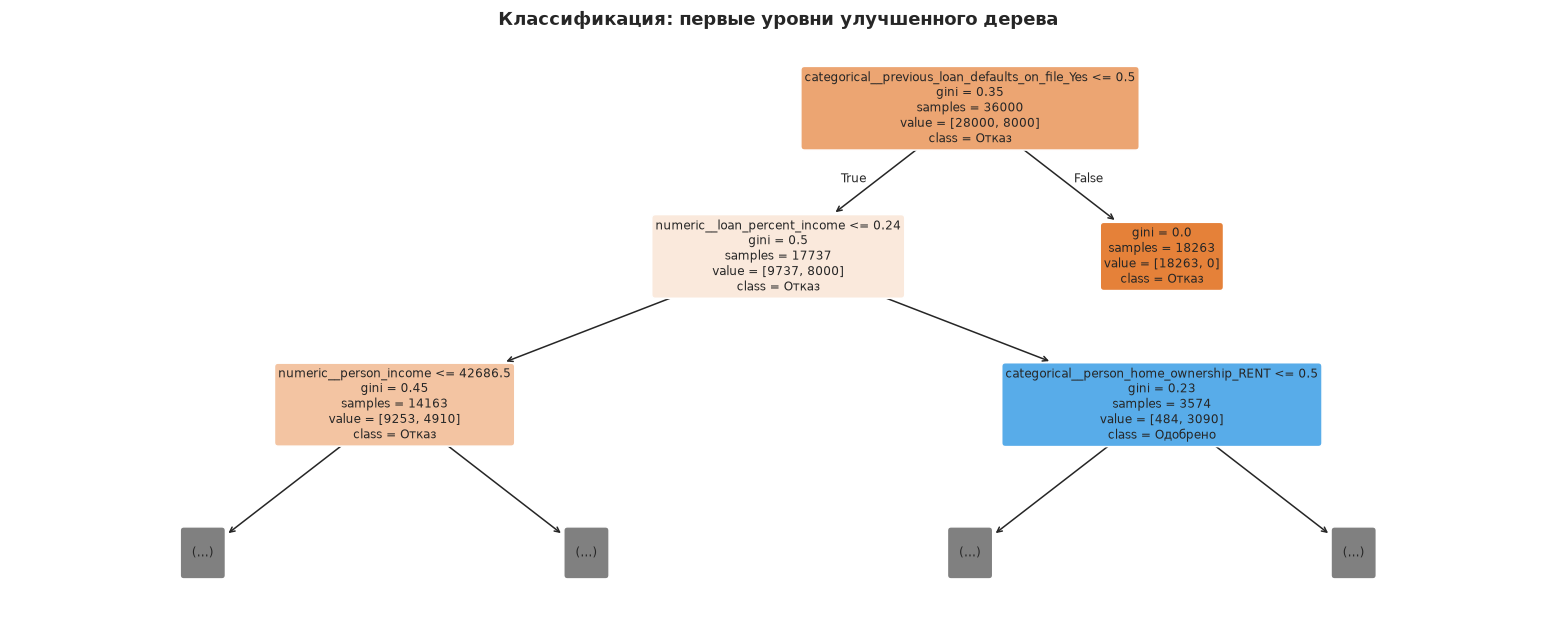

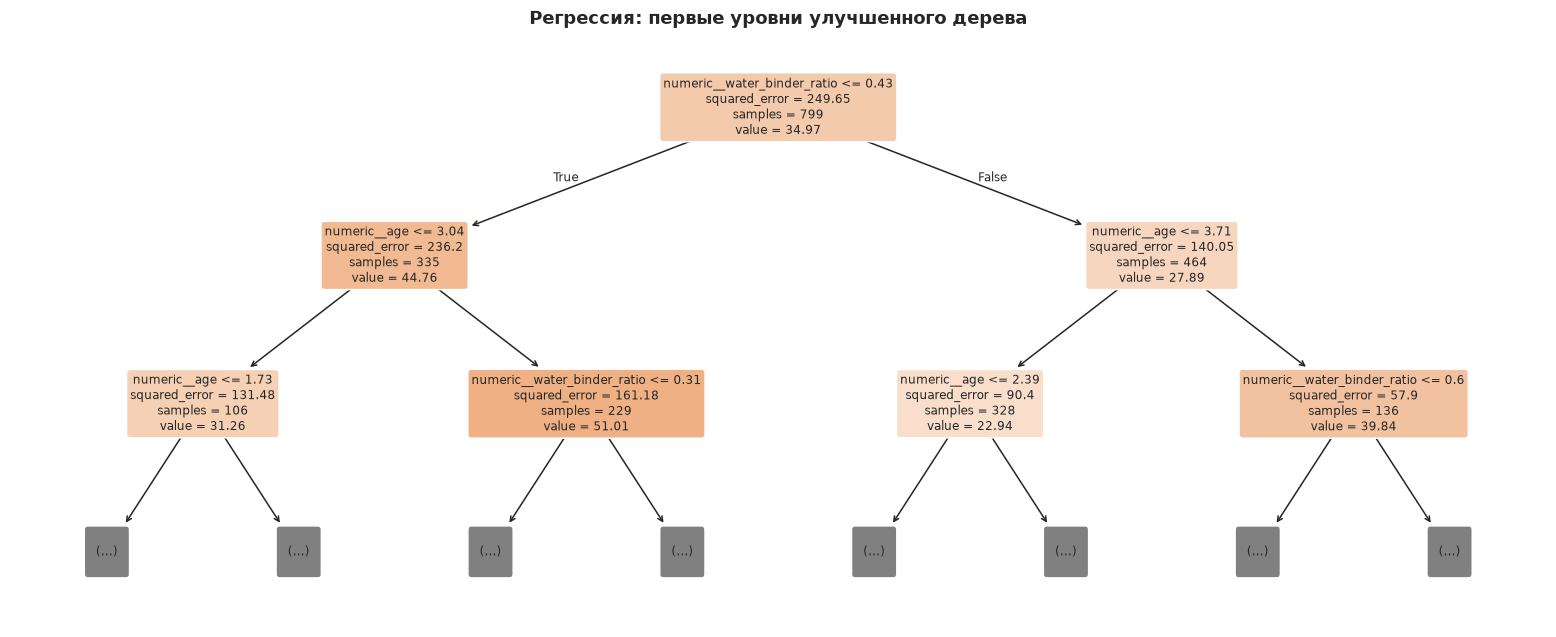

Задача,Модель,Признак,Важность
Классификация,sklearn · улучшенная,previous_loan_defaults_on_file,0.4313
Классификация,sklearn · улучшенная,loan_percent_income,0.1918
Классификация,sklearn · улучшенная,person_income,0.1798
Классификация,sklearn · улучшенная,person_home_ownership,0.0692
Классификация,sklearn · улучшенная,loan_intent,0.0480
Классификация,sklearn · улучшенная,credit_score,0.0326
Классификация,sklearn · улучшенная,loan_amnt,0.0230
Классификация,sklearn · улучшенная,person_age,0.0090
Классификация,sklearn · улучшенная,person_emp_exp,0.0054
Классификация,sklearn · улучшенная,cb_person_cred_hist_length,0.0053


Задача,Модель,Признак,Важность
Регрессия,sklearn · улучшенная,water_binder_ratio,0.3906
Регрессия,sklearn · улучшенная,age,0.3828
Регрессия,sklearn · улучшенная,cement,0.0694
Регрессия,sklearn · улучшенная,binder,0.0375
Регрессия,sklearn · улучшенная,superplasticizer,0.0321
Регрессия,sklearn · улучшенная,fly_ash,0.0227
Регрессия,sklearn · улучшенная,aggregate_binder_ratio,0.0181
Регрессия,sklearn · улучшенная,water,0.0172
Регрессия,sklearn · улучшенная,fine_aggregate,0.0120
Регрессия,sklearn · улучшенная,coarse_aggregate,0.0115


In [19]:
# Визуализация sklearn; собственные важности рассчитаны тем же определением CART.
importance_rows = []
for task in tasks:
    pipe = fitted[task, "sklearn_improved"]
    names = pipe.named_steps["preprocess"].get_feature_names_out()
    estimator = pipe.named_steps["model"]
    fig, ax = plt.subplots(figsize=(18, 7))
    plot_tree(estimator, max_depth=2, feature_names=list(names), filled=True,
              class_names=["Отказ", "Одобрено"] if task == "classification" else None,
              rounded=True, precision=2, fontsize=8, ax=ax)
    ax.set_title(TASK_NAMES[task] + ": первые уровни улучшенного дерева")
    plt.show()
    for name in ["sklearn_improved", "custom_improved"]:
        model = fitted[task, name]
        for feature, importance in zip(model.named_steps["preprocess"].get_feature_names_out(),
                                       model.named_steps["model"].feature_importances_):
            original = feature.split("__", 1)[1]
            original = next((column for column in CATEGORICAL if original.startswith(column + "_")), original)
            importance_rows.append({"task": task, "model": name, "Признак": original, "Важность": importance})
importance = pd.DataFrame(importance_rows).groupby(["task", "model", "Признак"], as_index=False)["Важность"].sum()
importance.to_csv(RESULTS / "feature_importances.csv", index=False)
for task in tasks:
    show_table(importance[(importance.task == task) & (importance.model == "sklearn_improved")]
               .sort_values("Важность", ascending=False).head(10).reset_index(drop=True), TASK_NAMES[task])

## 5. Сравнение результатов

Сравню все четыре варианта по основным метрикам, затем добавлю улучшенные KNN
и линейные модели из прошлых работ. Для F1 положительная разность означает улучшение,
для MAE — ухудшение. Совпадение данных и разбиений проверю до сравнения.

In [20]:
# Сравню варианты внутри работы, затем добавлю улучшенный KNN для ориентира.
comparison_rows, previous_rows = [], []
pairs = [("sklearn_improved", "sklearn_baseline", "Улучшение sklearn"),
         ("custom_baseline", "sklearn_baseline", "Своя и sklearn: исходные"),
         ("custom_improved", "sklearn_improved", "Своя и sklearn: улучшенные"),
         ("custom_improved", "custom_baseline", "Улучшение своей модели")]

for task in tasks:
    m = metrics[metrics.task == task].set_index("model")
    metric = "f1" if task == "classification" else "mae"
    for left, right, label in pairs:
        comparison_rows.append({"task": task, "comparison": label,
                                "metric": "F1" if metric == "f1" else "MAE, МПа",
                                "delta": m.loc[left, metric] - m.loc[right, metric]})
    for number in [1, 2, 3]:
        frame = metrics if number == 3 else pd.read_csv(ROOT / f"lab_{number}" / "results" / "metrics.csv")
        row = frame[(frame.task == task) & (frame.model == "sklearn_improved")].iloc[0]
        for field, expected in [("split_sha", tasks[task]["split_sha"]),
                                ("dataset_sha", tasks[task]["spec"]["sha256"]),
                                ("protocol_id", tasks[task]["spec"]["protocol_id"]),
                                ("feature_set", ",".join(tasks[task]["X_train"].columns))]:
            assert row[field] == expected
        previous_rows.append({"lab": number, "task": task, "algorithm": row.algorithm,
                              "metric": "F1" if metric == "f1" else "MAE, МПа", "Значение": row[metric]})
show_table(pd.DataFrame(comparison_rows), "Изменение основных метрик")
show_table(pd.DataFrame(previous_rows), "Улучшенные sklearn из работ №1–3")
show_table(metrics[["task", "model", "fit_seconds", "predict_seconds"]].reset_index(drop=True), "Время всего Pipeline")

Задача,Сравнение,Метрика,Изменение
Классификация,Улучшение sklearn,F1,0.0050
Классификация,Своя и sklearn: исходные,F1,-0.0074
Классификация,Своя и sklearn: улучшенные,F1,-0.0003
Классификация,Улучшение своей модели,F1,0.0122
Регрессия,Улучшение sklearn,"MAE, МПа",-1.3940
Регрессия,Своя и sklearn: исходные,"MAE, МПа",-0.0783
Регрессия,Своя и sklearn: улучшенные,"MAE, МПа",0.3230
Регрессия,Улучшение своей модели,"MAE, МПа",-0.9927


Работа,Задача,Алгоритм,Метрика,Значение
1,Классификация,KNN,F1,0.6960
2,Классификация,LogisticRegression,F1,0.7157
3,Классификация,DecisionTreeClassifier,F1,0.7376
1,Регрессия,KNN,"MAE, МПа",4.4187
2,Регрессия,LinearRegression,"MAE, МПа",4.8704
3,Регрессия,DecisionTreeRegressor,"MAE, МПа",4.4701


Задача,Модель,"Обучение, с","Прогноз, с"
Классификация,Dummy,0.0401,0.0069
Классификация,sklearn · исходная,0.1229,0.0088
Регрессия,Dummy,0.0024,0.0011
Регрессия,sklearn · исходная,0.0044,0.0013
Классификация,sklearn · улучшенная,0.1152,0.0085
Регрессия,sklearn · улучшенная,0.0069,0.0023
Классификация,своя · исходная,1.4727,0.0174
Регрессия,своя · исходная,0.1143,0.0030
Классификация,своя · улучшенная,0.5574,0.0107
Регрессия,своя · улучшенная,0.1155,0.0035


### Сохранение протокола и итоговые графики

Сохраню параметры, версии, критерии и правила выбора. В `results` также находятся
метрики, предсказания, все CV-оценки, разбиения, состав фолдов и характеристики деревьев.
Общий `comparison.ipynb` прочитает эти метрики и включит работу №3 автоматически.

Модель,F1 ↑,Precision,Recall
sklearn · исходная,0.7326,0.7263,0.7390
sklearn · улучшенная,0.7376,0.7839,0.6965
своя · исходная,0.7252,0.7157,0.7350
своя · улучшенная,0.7374,0.7827,0.6970


Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
sklearn · исходная,5.8641,9.2407,0.7354
sklearn · улучшенная,4.4701,7.0349,0.8466
своя · исходная,5.7859,9.0571,0.7458
своя · улучшенная,4.7932,7.5049,0.8254


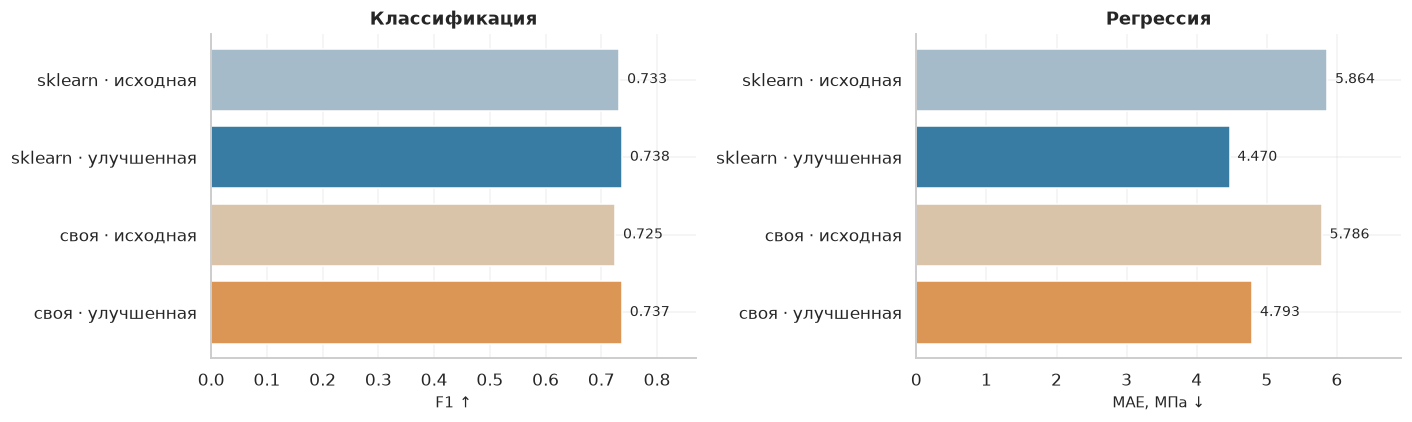

In [21]:
# Протокол содержит достаточно информации, чтобы проверить сопоставимость с лабораторной №1.
protocol = {"lab": 3, "seed": SEED, "cv_folds": 3, "selected": selected,
            "selection": "joint full-train CV of representations and hyperparameters; test reporting only",
            "classification_threshold": 0.5, "classification_tie": "first class (0)",
            "criteria": {"classification": "gini", "regression": "squared_error"}, "datasets": {},
            "versions": {"python": platform.python_version(), "numpy": np.__version__,
                         "pandas": pd.__version__, "sklearn": sklearn.__version__}}
reference = json.loads((ROOT / "lab_1" / "results" / "protocol.json").read_text())
for task, t in tasks.items():
    protocol["datasets"][task] = reference["datasets"][task]
(RESULTS / "protocol.json").write_text(json.dumps(protocol, ensure_ascii=False, indent=2))
for task in tasks:
    columns = ["model", "f1", "precision", "recall"] if task == "classification" else ["model", "mae", "rmse", "r2"]
    show_table(metrics.loc[(metrics.task == task) & (metrics.stage != "dummy"), columns].reset_index(drop=True), TASK_NAMES[task])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task, metric in zip(axes, ["classification", "regression"], ["f1", "mae"]):
    group = metrics[(metrics.task == task) & (metrics.stage != "dummy")]
    bars = ax.barh([MODEL_NAMES[name] for name in group.model], group[metric],
                   color=["#a6bbc9", "#387ca3", "#d9c4aa", "#db9655"])
    ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=9)
    ax.set(title=TASK_NAMES[task], xlabel="F1 ↑" if metric == "f1" else "MAE, МПа ↓")
    ax.set_xlim(0, group[metric].max() * 1.18)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Выводы по всем этапам

Ниже соберу численные итоги исходного и улучшенного sklearn, собственной реализации
до и после переноса улучшений, а также сравнение с предыдущими алгоритмами.
Числа в выводах берутся из проведённых экспериментов и сохраняются в выводе ячейки.

In [22]:
# Все утверждения о качестве опираются на результаты этого запуска.
for task in tasks:
    metric = "f1" if task == "classification" else "mae"
    title = "F1" if task == "classification" else "MAE, МПа"
    m = metrics[metrics.task == task].set_index("model")
    config = selected[task]
    old, improved = m.loc["sklearn_baseline", metric], m.loc["sklearn_improved", metric]
    own_old, own_new = m.loc["custom_baseline", metric], m.loc["custom_improved", metric]
    better = improved > old if task == "classification" else improved < old
    own_better = own_new > own_old if task == "classification" else own_new < own_old
    base_cv = hypotheses[(hypotheses.task == task) & (hypotheses["mode"] == "raw")].iloc[0].cv_mean
    display(Markdown(
        f"**{TASK_NAMES[task]}.** Исходный sklearn: **{title} = {old:.5f}**, "
        f"улучшенный: **{improved:.5f}**; изменение **{improved-old:+.5f}**. "
        f"На данном test {'получено улучшение' if better else 'улучшения не получено'}. "
        f"CV-score изменился с **{base_cv:.5f}** до **{config['cv_score']:.5f}** "
        f"(для регрессии это отрицательная MAE). Выбраны признаки `{config['mode']}` "
        f"и параметры `{config['params']}`.\n\n"
        f"Своя исходная модель: **{own_old:.5f}**, разность со sklearn **{own_old-old:+.5f}**. "
        f"После переноса улучшений своя модель: **{own_new:.5f}**, "
        f"изменение **{own_new-own_old:+.5f}**; {'качество улучшилось' if own_better else 'выигрыша на test нет'}. "
        f"Разность с улучшенным sklearn: **{own_new-improved:+.5f}**. "
        "Различия при одинаковых настройках показывают чувствительность жадного дерева "
        "к равноценным разбиениям и вычислениям с плавающей точкой."))
    prior = pd.DataFrame(previous_rows).query("task == @task")
    best = prior.sort_values("Значение", ascending=task == "regression").iloc[0]
    display(Markdown(f"Среди улучшенных sklearn работ №1–3 на этом test лучший результат "
                     f"у **{best.algorithm} (№{int(best.lab)})**: **{best['Значение']:.5f}**. "
                     "Предобработка между алгоритмами различается, поэтому сравниваются полные решения."))

**Классификация.** Исходный sklearn: **F1 = 0.73259**, улучшенный: **0.73762**; изменение **+0.00503**. На данном test получено улучшение. CV-score изменился с **0.70979** до **0.72686** (для регрессии это отрицательная MAE). Выбраны признаки `raw` и параметры `{'max_depth': None, 'min_samples_leaf': 20, 'class_weight': None}`.

Своя исходная модель: **0.72521**, разность со sklearn **-0.00738**. После переноса улучшений своя модель: **0.73737**, изменение **+0.01216**; качество улучшилось. Разность с улучшенным sklearn: **-0.00025**. Различия при одинаковых настройках показывают чувствительность жадного дерева к равноценным разбиениям и вычислениям с плавающей точкой.

Среди улучшенных sklearn работ №1–3 на этом test лучший результат у **DecisionTreeClassifier (№3)**: **0.73762**. Предобработка между алгоритмами различается, поэтому сравниваются полные решения.

**Регрессия.** Исходный sklearn: **MAE, МПа = 5.86415**, улучшенный: **4.47014**; изменение **-1.39401**. На данном test получено улучшение. CV-score изменился с **-5.85267** до **-5.25423** (для регрессии это отрицательная MAE). Выбраны признаки `engineered` и параметры `{'max_depth': 12, 'min_samples_leaf': 1}`.

Своя исходная модель: **5.78587**, разность со sklearn **-0.07828**. После переноса улучшений своя модель: **4.79315**, изменение **-0.99271**; качество улучшилось. Разность с улучшенным sklearn: **+0.32301**. Различия при одинаковых настройках показывают чувствительность жадного дерева к равноценным разбиениям и вычислениям с плавающей точкой.

Среди улучшенных sklearn работ №1–3 на этом test лучший результат у **KNN (№1)**: **4.41873**. Предобработка между алгоритмами различается, поэтому сравниваются полные решения.

### Итог проведённых экспериментов

**Гипотезы.** Масштабирование и log не дали существенного выигрыша исходному дереву.
Отношения признаков помогли регрессии: CV MAE снизилась с 5,857 для `log` до 5,270 МПа
для `engineered`; в классификации добавление отношений средний F1 не улучшило.
Лучшая конфигурация с `balanced` уступила лучшей с обычными весами по CV F1 на 0,01648.
Ограничение роста улучшило лучший CV-score относительно лучших неограниченных деревьев
на 0,01707 F1 и на 0,01619 МПа соответственно. Для бетона основная часть улучшения
пришла от признаков, а дополнительный эффект ограничения глубины оказался небольшим.

**Классификация.** У sklearn F1 выросла с **0,73259 до 0,73762**.
Выбраны исходные признаки, обычные веса, `max_depth=None`, `min_samples_leaf=20`.
Число листьев сократилось с **2861 до 527**, а train F1 — с 1 до 0,80437.
Precision выросла с **72,63% до 78,39%**, recall снизилась с **73,90% до 69,65%**:
получился более осторожный классификатор с небольшим выигрышем F1.
У своей модели F1 выросла с **0,72521 до 0,73737**; улучшенная версия практически
совпала со sklearn по F1, хотя на **0,0667%** заявок классы различаются.

**Регрессия.** У sklearn MAE снизилась с **5,86415 до 4,47014 МПа**.
Выбраны `engineered`, `max_depth=12`, `min_samples_leaf=1`; число листьев снизилось
с **784 до 551**. У своей модели MAE снизилась с **5,78587 до 4,79315 МПа**.
Перенос улучшений помог, однако своя улучшенная модель уступила sklearn на **0,32301 МПа**.
Проверка критериев в сопоставимых узлах подтверждает равноценность разных правил;
она объясняет расхождения, но не отменяет фактическую разницу качества.

**Сравнение с №1–2.** Улучшенное дерево sklearn стало лучшим из трёх алгоритмов
в классификации: **F1 0,73762** против **0,71574** у логистической регрессии
и **0,69597** у KNN. Для бетона KNN сохранил минимальную MAE — **4,419 МПа**,
дерево получило **4,470 МПа**, улучшенная линейная модель — **4,870 МПа**.
Разница KNN и дерева небольшая и сама по себе не доказывает устойчивого преимущества.


### Общий вывод и ограничения

Я выполнил все этапы исследования: обучил исходные деревья sklearn для обеих задач,
оценил метрики, сформулировал и проверил гипотезы на CV, выбрал улучшенные конфигурации,
написал CART на NumPy, обучил свою модель до и после переноса улучшений и сравнил все варианты.
Численные выводы по каждому этапу приведены выше.

Для дерева ключевой способ управления обобщением — ограничение сложности. Масштабирование
не меняет порядок значений признака; отличия результатов могут появляться из-за float32,
равноценных разбиений и выбора порога между наблюдениями. При log-преобразовании середина
интервала в преобразованной шкале соответствует другому порогу в исходной шкале, поэтому
предсказания для новых значений могут отличаться даже при одинаковом разбиении train.
Новые отношения признаков меняют доступные направления разбиения; их полезность оценивается по CV.

Веса `balanced` меняют критерий и доли классов в листьях, поэтому их вероятности не следует
автоматически считать калиброванными вероятностями одобрения в исходной популяции.
Самостоятельная реализация воспроизводит математику CART, но другой порядок разрешения
равенств может менять глубокие ветви. Отдельно измеренные различия ответов позволяют
оценивать этот эффект, не требуя искусственного совпадения со sklearn.

Оценки относятся к одному фиксированному test. После просмотра результатов трёх лабораторных
этот test постепенно становится общим исследовательским ориентиром; для окончательного выбора
нужен новый holdout или вложенная CV. Кредитный набор синтетический и не доказывает качество
на реальных заявках. Разделение бетона по рецептурам исключает точные совпадения смесей между
частями, но не делает близкие смеси независимыми. Важности не устанавливают причинность.

### Повторный запуск

Результаты, таблицы, графики и выводы уже сохранены в notebook. Для повторения из корня:
`python run_notebooks.py --labs 3` в общем окружении репозитория. Можно открыть этот notebook
из корня или папки `lab_3` и выполнить **Run All**. Нужны файлы данных, разбиений и протокола №1;
метрики №1–2 нужны для итогового сравнения. Весь вычислительный код показан в ячейках.
Проверка алгоритма: `python -m pytest -q`.

Источники данных и условия использования приведены в начале и в
[описании данных](../lab_1/data/README.md). Результаты всех выполненных работ собраны
в отдельном [comparison.ipynb](../comparison.ipynb); работы №4–5 добавятся после выполнения.